# Pandas – analiza danych tabelarycznych

Pandas to podstawowa biblioteka Pythona do pracy z danymi w postaci **tabel** (jak arkusz Excela lub tabela SQL). Prawie każdy projekt ML zaczyna się od Pandas: wczytanie danych, czyszczenie, filtrowanie, grupowanie, łączenie tabel.

**Plan notatnika:**
1. `Series` – kolumna danych z indeksem
2. `DataFrame` – tabela
3. Wczytywanie i zapis danych, pierwszy rzut oka na dane
4. Selekcja: kolumny, wiersze, filtrowanie
5. Tworzenie i przekształcanie kolumn
6. Braki danych
7. Grupowanie (`groupby`)
8. Łączenie tabel (`concat`, `merge`, `join`)
9. Daty i szeregi czasowe
10. Pandas a SQL
11. Pandas 3: kopie, widoki i typowe pułapki

**Przydatne linki:** [strona Pandas](https://pandas.pydata.org/), [dokumentacja](https://pandas.pydata.org/pandas-docs/stable/), [cheat sheet](https://pandas.pydata.org/Pandas_Cheat_Sheet.pdf).

## Dlaczego Pandas?

Z poprzedniego notatnika wiesz, że NumPy świetnie liczy na tablicach liczb. Prawdziwe dane są jednak bardziej „kłopotliwe”:
- kolumny mają **nazwy**, a wiersze mogą mieć **etykiety** (np. daty, identyfikatory klientów),
- w jednej tabeli są **różne typy** (liczby, tekst, daty, wartości logiczne),
- w danych są **braki** (`NaN`),
- dane trzeba **wczytać** z plików, łączyć, grupować i podsumowywać.

Pandas jest zbudowany na NumPy – każda kolumna to w środku tablica NumPy, ale z indeksem, nazwą i mnóstwem wygodnych metod.

In [1]:
import numpy as np
import pandas as pd

pd.__version__

'3.0.5'

> **Pandas 3.** W tym szkoleniu używamy Pandas w wersji 3.x. W wielu starszych tutorialach z Internetu kod działa inaczej (np. `s[0]` dla indeksu tekstowego, `fillna(inplace=True)` na kolumnie, typ `object` dla tekstu). Takie miejsca oznaczamy ramką **Pandas 3**, a podsumowanie jest w ostatniej sekcji.

## 1. `Series` – kolumna danych z indeksem

`Series` to jednowymiarowa tablica z **etykietowanym indeksem**. Może przechowywać liczby, tekst, wartości logiczne, daty… Każda kolumna tabeli (`DataFrame`) jest obiektem `Series`, więc zrozumienie go jest kluczowe.

In [2]:
s = pd.Series(data=[1, 2, 3])
s

0    1
1    2
2    3
dtype: int64

Po lewej widać **indeks** (domyślnie `0, 1, 2…`), po prawej **wartości**, na dole **typ danych** (`dtype`). Indeks i nazwę można nadać samodzielnie:

In [3]:
s = pd.Series(data=[1, 2, 3], index=['a', 'b', 'c'], name='test')
s

a    1
b    2
c    3
Name: test, dtype: int64

In [4]:
s = pd.Series(data=[1, np.nan, 3], index=['a', 'b', 'c'], name='test')  # NaN = brak danych
s

a    1.0
b    NaN
c    3.0
Name: test, dtype: float64

Wartość brakująca `NaN` jest liczbą zmiennoprzecinkową, dlatego typ całej serii zmienił się na `float64`. Inne typy:

In [5]:
pd.Series(data=[True, False, True])

0     True
1    False
2     True
dtype: bool

In [6]:
pd.Series(data=['python', 'sas', 'r'], name='jezyki')   # tekst: typ `str`

0    python
1       sas
2         r
Name: jezyki, dtype: str

In [7]:
s = pd.Series(data=np.arange(1, 11), index=pd.date_range(start='2025-05-21', periods=10))
s

2025-05-21     1
2025-05-22     2
2025-05-23     3
2025-05-24     4
2025-05-25     5
2025-05-26     6
2025-05-27     7
2025-05-28     8
2025-05-29     9
2025-05-30    10
Freq: D, dtype: int64

Najważniejsze atrybuty serii: `dtype`, `index` (obiekt `pd.Index`) i `values` / `to_numpy()` (zwykła tablica NumPy).

In [8]:
s.dtype

dtype('int64')

In [9]:
s.index

DatetimeIndex(['2025-05-21', '2025-05-22', '2025-05-23', '2025-05-24',
               '2025-05-25', '2025-05-26', '2025-05-27', '2025-05-28',
               '2025-05-29', '2025-05-30'],
              dtype='datetime64[us]', freq='D')

In [10]:
s.to_numpy()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10])

### Series a tablica NumPy

`Series` uogólnia jednowymiarową tablicę NumPy:
- tablica NumPy ma tylko numerację pozycyjną `0, 1, 2…`,
- `Series` ma numerację pozycyjną **oraz** indeks etykiet (dowolne napisy, liczby, daty).

In [11]:
s = pd.Series([3, 1, 2.71, -10], index=['a', 'b', 'c', 'd'])
s['c']

np.float64(2.71)

Indeks etykiet może nie być uporządkowany, mieć luki i **powtórzenia** (inaczej niż klucze słownika):

In [12]:
pd.Series([3, 1, 2.71, -10, 50], index=[3, 2, 5, 2, 100])

3       3.00
2       1.00
5       2.71
2     -10.00
100    50.00
dtype: float64

### Series jako słownik

Klucze słownika stają się etykietami indeksu:

In [13]:
ludność_dict = {'Polska': 38501,
                'Czechy': 10221,
                'Szwecja': 9045,
                'Niemcy': 82370,
                'Litwa': 3565}   # tys. mieszkańców

ludność = pd.Series(ludność_dict)
ludność

Polska     38501
Czechy     10221
Szwecja     9045
Niemcy     82370
Litwa       3565
dtype: int64

In [14]:
ludność['Polska']     # pojedyncza wartość wyświetla się jako np.int64(...) – to zwykła liczba (typ NumPy)

np.int64(38501)

In [15]:
ludność.Polska   # dostęp przez atrybut działa tylko, gdy etykieta jest poprawną nazwą zmiennej

np.int64(38501)

In [16]:
'Polska' in ludność, 'Francja' in ludność

(True, False)

In [17]:
list(ludność.items())   # pary (etykieta, wartość), jak w słowniku

[('Polska', 38501),
 ('Czechy', 10221),
 ('Szwecja', 9045),
 ('Niemcy', 82370),
 ('Litwa', 3565)]

Podobnie jak słownik, `Series` można rozszerzać (modyfikacja w miejscu):

In [18]:
ludność['Grecja'] = 10723
ludność

Polska     38501
Czechy     10221
Szwecja     9045
Niemcy     82370
Litwa       3565
Grecja     10723
dtype: int64

### Selekcja elementów: `loc` i `iloc`

`Series` łączy cechy słownika (dostęp po etykiecie) i tablicy (dostęp po pozycji). Żeby uniknąć niejednoznaczności, używamy dwóch jawnych indekserów:

- **`.loc[...]`** – zawsze **etykiety**; wycinek `a:b` obejmuje **oba końce**,
- **`.iloc[...]`** – zawsze **pozycje** `0, 1, 2…`; wycinek `a:b` **wyklucza** prawy koniec (jak w Pythonie i NumPy).

In [19]:
ludność.loc['Czechy':'Niemcy']     # po etykietach: prawy kraniec WŁĄCZONY

Czechy     10221
Szwecja     9045
Niemcy     82370
dtype: int64

In [20]:
ludność.iloc[1:3]                  # po pozycjach: prawy kraniec wykluczony

Czechy     10221
Szwecja     9045
dtype: int64

In [21]:
ludność.loc[['Czechy', 'Grecja', 'Litwa']]   # lista etykiet (fancy indexing)

Czechy    10221
Grecja    10723
Litwa      3565
dtype: int64

In [22]:
ludność.iloc[[2, 4, 2]]                      # lista pozycji (może się powtarzać)

Szwecja    9045
Litwa      3565
Szwecja    9045
dtype: int64

In [23]:
ludność[(10_000 < ludność) & (ludność < 40_000)]   # maska logiczna, jak w NumPy (& zamiast and)

Polska    38501
Czechy    10221
Grecja    10723
dtype: int64

> **Pandas 3: zagadka.** Seria z indeksem **liczbowym** `1, 2, 3` – co zwróci `s[2]`, a co `s[1:3]`? Dlatego zawsze jawnie piszemy `loc` albo `iloc`.

In [24]:
s = pd.Series(['a', 'b', 'c'], index=[1, 2, 3])
s

1    a
2    b
3    c
dtype: str

In [25]:
s.loc[1], s.iloc[1]     # etykieta 1 -> 'a', pozycja 1 -> 'b'

('a', 'b')

In [26]:
s.iloc[1:3]    # pozycje 1 i 2 (prawy koniec wykluczony)

2    b
3    c
dtype: str

In [27]:
s.loc[1:3]     # etykiety 1, 2, 3 (prawy koniec włączony)

1    a
2    b
3    c
dtype: str

> **Pandas 3.** W starszych wersjach `s[0]` dla serii z indeksem tekstowym „po cichu” działało jak pozycja (`iloc`). W Pandas 3 ten skrót został usunięty i dostajemy błąd `KeyError`.

In [28]:
ceny_akcji = pd.Series(data={'Orlen': 70, 'PZU': 30, 'KGHM': 100})
try:
    ceny_akcji[0]
except KeyError as e:
    print("KeyError:", e)
ceny_akcji.iloc[0]    # tak należy pobrać pierwszy element

KeyError: 0


np.int64(70)

### Statystyki i operacje na serii

Serie mają wiele gotowych metod: liczą statystyki, sortują, rangują. Operacje arytmetyczne działają na całej serii naraz (wektorowo, jak w NumPy).

In [29]:
ceny_akcji.agg(['count', 'sum', 'mean', 'min', 'max', 'std'])   # kilka statystyk naraz

count      3.000000
sum      200.000000
mean      66.666667
min       30.000000
max      100.000000
std       35.118846
dtype: float64

In [30]:
ceny_akcji.describe()

count      3.000000
mean      66.666667
std       35.118846
min       30.000000
25%       50.000000
50%       70.000000
75%       85.000000
max      100.000000
dtype: float64

In [31]:
ceny_akcji.idxmax(), ceny_akcji.idxmin()    # ETYKIETA największej / najmniejszej wartości (odpowiednik argmax)

('KGHM', 'PZU')

In [32]:
ceny_akcji.nlargest(2)

KGHM     100
Orlen     70
dtype: int64

In [33]:
ceny_akcji.sort_values(ascending=False)

KGHM     100
Orlen     70
PZU       30
dtype: int64

In [34]:
ceny_akcji.rank()    # pozycja w rankingu rosnącym (1 = najmniejsza)

Orlen    2.0
PZU      1.0
KGHM     3.0
dtype: float64

In [35]:
ceny_akcji * 1.1     # operacja na całej serii

Orlen     77.0
PZU       33.0
KGHM     110.0
dtype: float64

**Wyrównywanie po indeksie.** Przy działaniach na dwóch seriach Pandas łączy elementy o **tych samych etykietach**, a nie po pozycjach. Brak pary daje `NaN`:

In [36]:
akcje_dzis = pd.Series({'Orlen': 70, 'PZU': 30, 'KGHM': 100})
akcje_wczoraj = pd.Series({'KGHM': 98, 'Orlen': 71, 'CDR': 200})
akcje_dzis - akcje_wczoraj

CDR      NaN
KGHM     2.0
Orlen   -1.0
PZU      NaN
dtype: float64

`value_counts()` zlicza, ile razy występuje każda wartość – bardzo często używana na kolumnach tekstowych i kategorialnych:

In [37]:
pd.Series(['tak', 'nie', 'tak', 'tak', 'nie']).value_counts()

tak    3
nie    2
Name: count, dtype: int64

## 2. `DataFrame` – tabela

`DataFrame` to dwuwymiarowa tabela: **kolumny to zmienne (cechy), wiersze to obserwacje**. Każda kolumna jest obiektem `Series`, a wszystkie kolumny dzielą ten sam indeks wierszy. Kolumny mogą mieć różne typy.

Zbudujmy tabelę z dwóch serii o wspólnych etykietach (krajach):

In [38]:
powierzchnia_dict = {'Polska': 322.6,
                     'Czechy': 78.9,
                     'Szwecja': 450,
                     'Niemcy': 357,
                     'Litwa': 65.3}   # tys. km2

powierzchnia = pd.Series(powierzchnia_dict)
ludność = pd.Series(ludność_dict)

kraje = pd.DataFrame({'powierzchnia': powierzchnia,
                      'ludność': ludność})
kraje

,powierzchnia,ludność
Polska,322.6,38501
Czechy,78.9,10221
Szwecja,450.0,9045
Niemcy,357.0,82370
Litwa,65.3,3565


`DataFrame` ma dwa indeksy – wierszy (`index`) i kolumn (`columns`) – oba są obiektami `pd.Index`. Przydatne atrybuty:

In [39]:
kraje.index

Index(['Polska', 'Czechy', 'Szwecja', 'Niemcy', 'Litwa'], dtype='str')

In [40]:
kraje.columns

Index(['powierzchnia', 'ludność'], dtype='str')

In [41]:
kraje.shape, kraje.ndim, kraje.size     # (wiersze, kolumny)

((5, 2), 2, 10)

In [42]:
kraje.dtypes

powierzchnia    float64
ludność           int64
dtype: object

In [43]:
kraje.to_numpy()    # zwykła tablica NumPy

array([[3.2260e+02, 3.8501e+04],
       [7.8900e+01, 1.0221e+04],
       [4.5000e+02, 9.0450e+03],
       [3.5700e+02, 8.2370e+04],
       [6.5300e+01, 3.5650e+03]])

### Kolumna jako `Series`, nowa kolumna

Tabela zachowuje się jak słownik, którego klucze to nazwy kolumn:

In [44]:
kraje['powierzchnia']      # jedna kolumna = Series

Polska     322.6
Czechy      78.9
Szwecja    450.0
Niemcy     357.0
Litwa       65.3
Name: powierzchnia, dtype: float64

In [45]:
kraje.powierzchnia         # to samo (działa, gdy nazwa kolumny jest poprawną nazwą zmiennej i nie koliduje z metodą DataFrame)

Polska     322.6
Czechy      78.9
Szwecja    450.0
Niemcy     357.0
Litwa       65.3
Name: powierzchnia, dtype: float64

In [46]:
type(kraje['powierzchnia']), type(kraje[['powierzchnia']])   # podwójne nawiasy dają DataFrame z jedną kolumną

(pandas.Series, pandas.DataFrame)

Nową kolumnę tworzymy przypisaniem – zwykle jako wynik działań na innych kolumnach:

In [47]:
kraje['gęstość zaludnienia'] = kraje.ludność / kraje.powierzchnia
kraje

,powierzchnia,ludność,gęstość zaludnienia
Polska,322.6,38501,119.345939
Czechy,78.9,10221,129.543726
Szwecja,450.0,9045,20.100000
Niemcy,357.0,82370,230.728291
Litwa,65.3,3565,54.594181


### Inne sposoby tworzenia `DataFrame`

In [48]:
pd.DataFrame({'imię': ['Ala', 'Ola', 'Ela'],
              'wiek': [25, 31, 28],
              'czy_klient': [True, False, True]})       # ze słownika list (najczęstszy sposób)

,imię,wiek,czy_klient
0,Ala,25,True
1,Ola,31,False
2,Ela,28,True


In [49]:
pd.DataFrame([['Ala', 25], ['Ola', 31], ['Ela', 28]], columns=['imię', 'wiek'])   # z listy list

,imię,wiek
0,Ala,25
1,Ola,31
2,Ela,28


In [50]:
list_dict = [{'a': 1, 'b': 2, 'c': 100},
             {'b': 10, 'c': 'Ala'},
             {'a': 0, 'b': 0, 'c': 1, 'd': 2}]
pd.DataFrame(list_dict)          # z listy słowników (brakujące klucze -> NaN)

,a,b,c,d
0,1.0,2,100,NaN
1,NaN,10,Ala,NaN
2,0.0,0,1,2.0


In [51]:
arr = np.arange(10).reshape(5, 2)
pd.DataFrame(arr, index=['a', 'b', 'c', 'd', 'e'], columns=['X', 'Y'])    # z tablicy NumPy 2D

,X,Y
a,0,1
b,2,3
c,4,5
d,6,7
e,8,9


In [52]:
pd.DataFrame(ludność, columns=['ludność'])       # z jednej serii

,ludność
Polska,38501
Czechy,10221
Szwecja,9045
Niemcy,82370
Litwa,3565


### Indeks wierszy: `set_index`, `reset_index`

Kolumnę można zamienić w indeks wierszy i odwrotnie. Indeks to np. identyfikator klienta albo data. `reset_index()` przywraca domyślny indeks `0, 1, 2…`, a stary indeks wstawia jako kolumnę (`drop=True` zamiast tego go odrzuca).

In [53]:
kraje_kol = kraje.reset_index(names='kraj')
kraje_kol

,kraj,powierzchnia,ludność,gęstość zaludnienia
0,Polska,322.6,38501,119.345939
1,Czechy,78.9,10221,129.543726
2,Szwecja,450.0,9045,20.100000
3,Niemcy,357.0,82370,230.728291
4,Litwa,65.3,3565,54.594181


In [54]:
kraje_kol.set_index('kraj')

,powierzchnia,ludność,gęstość zaludnienia
kraj,,,
Polska,322.6,38501,119.345939
Czechy,78.9,10221,129.543726
Szwecja,450.0,9045,20.100000
Niemcy,357.0,82370,230.728291
Litwa,65.3,3565,54.594181


Wiersz (lub komórkę) pobieramy po etykiecie przez `.loc[wiersz]` / `.loc[wiersz, kolumna]` (pełny przegląd selekcji – w sekcji 4):

In [55]:
kraje.loc['Polska']

powierzchnia             322.600000
ludność                38501.000000
gęstość zaludnienia      119.345939
Name: Polska, dtype: float64

In [56]:
kraje.loc['Polska', 'ludność']

np.int64(38501)

### Zmiana nazw i usuwanie kolumn i wierszy

In [57]:
df = pd.DataFrame({'col one': [100, 200], 'col two': [300, 400]})
df

,col one,col two
0,100,300
1,200,400


In [58]:
df = df.rename(columns={'col one': 'col_one', 'col two': 'col_two'})   # zmiana wybranych nazw
df

,col_one,col_two
0,100,300
1,200,400


In [59]:
df.columns = ['a', 'b']     # zmiana wszystkich nazw naraz (lista musi mieć tyle elementów, ile kolumn)
df

,a,b
0,100,300
1,200,400


In [60]:
df['c'] = df['b'] * 2
df.drop(columns='c')       # usunięcie kolumny: zwraca NOWĄ tabelę

,a,b
0,100,300
1,200,400


In [61]:
df     # oryginał się nie zmienił, kolumna c nadal jest

,a,b,c
0,100,300,600
1,200,400,800


In [62]:
df = df.drop(columns='c')   # trwała zmiana = przypisanie wyniku do zmiennej (zalecany styl, zamiast inplace=True)
df

,a,b
0,100,300
1,200,400


In [63]:
df.drop(index=1)          # usunięcie wiersza o etykiecie 1

,a,b
0,100,300


Kolejność kolumn zmieniamy, wybierając je w nowej kolejności:

In [64]:
df[['b', 'a']]

,b,a
0,300,100
1,400,200


### Zrozumienie parametru `axis`

Wiele metod ma parametr `axis`, który określa kierunek operacji (to częste miejsce pomyłek, wiesz już z NumPy):
- `axis=0` (lub `'index'`) – operacja **w dół, po wierszach**; wynik to jedna wartość na **kolumnę** (np. suma kolumny). To zachowanie domyślne.
- `axis=1` (lub `'columns'`) – operacja **w poprzek, po kolumnach**; wynik to jedna wartość na **wiersz** (np. suma wszystkich kolumn dla klienta).

In [65]:
df = pd.DataFrame({'q1': [10, 20, 30], 'q2': [15, 25, 35], 'q3': [5, 5, 5]}, index=['A', 'B', 'C'])
df

,q1,q2,q3
A,10,15,5
B,20,25,5
C,30,35,5


In [66]:
df.sum()          # suma każdej kolumny (axis=0)

q1    60
q2    75
q3    15
dtype: int64

In [67]:
df.sum(axis=1)    # suma każdego wiersza

A    30
B    50
C    70
dtype: int64

In [68]:
df.mean()

q1    20.0
q2    25.0
q3     5.0
dtype: float64

---

### Czas na zadania 1–10

Otwórz notatnik `Zadania/1-10.ipynb` i rozwiąż ćwiczenia 1–10 (zakres: `Series` i `DataFrame`: tworzenie, konwersje, indeks, sekcje 1 i 2).

## 3. Wczytywanie i zapis danych, pierwszy rzut oka

W praktyce dane rzadko tworzymy ręcznie – **wczytujemy** je z plików: CSV, TXT, Excel, JSON, baz danych. Każdy format ma funkcję `pd.read_...()` (odczyt) i metodę `DataFrame.to_...()` (zapis).

| Format | Odczyt | Zapis |
|---|---|---|
| CSV / TXT | `pd.read_csv()` | `df.to_csv()` |
| Excel | `pd.read_excel()` (wymaga `openpyxl`) | `df.to_excel()` |
| JSON | `pd.read_json()` | `df.to_json()` |
| SQL | `pd.read_sql()` | `df.to_sql()` |
| Parquet | `pd.read_parquet()` | `df.to_parquet()` |

Przykładowe pliki w folderze notatnika zawierają pomiary bez nagłówków. Zobaczmy ich surową zawartość:

In [69]:
print(open('data.csv').read())
print('---')
print(open('data.txt').read())

2024-05-21,00:00:00,123.4
2024-05-21,00:01:00,123.5
2024-05-21,00:02:00,123.6

---
2024-05-21 12:00:00,2.3
2024-05-21 12:01:00,3.1
2024-05-21 12:02:00,2.7


Bez dodatkowych parametrów Pandas uzna pierwszy wiersz za nagłówek. Gdy plik **nie ma nagłówka**, podajemy `header=None` (kolumny dostaną numery) lub od razu nazwy w `names`:

In [70]:
pd.read_csv('data.csv', header=None)

,0,1,2
0,2024-05-21,00:00:00,123.4
1,2024-05-21,00:01:00,123.5
2,2024-05-21,00:02:00,123.6


In [71]:
df_csv = pd.read_csv('data.csv', header=None, names=['data', 'godzina', 'wynik'])
df_csv

,data,godzina,wynik
0,2024-05-21,00:00:00,123.4
1,2024-05-21,00:01:00,123.5
2,2024-05-21,00:02:00,123.6


Plik `data.txt` to też tekst rozdzielony przecinkami. Pierwsza kolumna zawiera datę **i** godzinę, więc od razu każemy Pandas zamienić ją na typ daty (`parse_dates`):

In [72]:
df_txt = pd.read_csv('data.txt', header=None, names=['czas', 'wynik'], parse_dates=['czas'])
df_txt

,czas,wynik
0,2024-05-21 12:00:00,2.3
1,2024-05-21 12:01:00,3.1
2,2024-05-21 12:02:00,2.7


In [73]:
df_txt.dtypes

czas     datetime64[us]
wynik           float64
dtype: object

Pliki Excela wczytujemy funkcją `read_excel` (potrzebny pakiet `openpyxl`; opcjonalnie `sheet_name='nazwa arkusza'`):

In [74]:
pd.read_excel('data.xlsx', header=None)

,0,1,2
0,2024-05-21,00:00:00,123.4
1,2024-05-21,00:15:00,154.3
2,2024-05-21,00:30:00,189.5


### Najczęstsze parametry `read_csv`

| Parametr | Do czego służy |
|---|---|
| `sep=';'` | separator kolumn (domyślnie przecinek; w polskim Excelu często średnik, tabulator to `'\t'`) |
| `decimal=','` | separator dziesiętny (w Polsce przecinek) |
| `header=None`, `names=[...]` | brak nagłówka / własne nazwy kolumn |
| `index_col=0` | która kolumna ma być indeksem |
| `usecols=[...]` | wczytaj tylko wybrane kolumny (oszczędność pamięci) |
| `nrows=100` | wczytaj tylko pierwsze 100 wierszy |
| `parse_dates=[...]` | zamień wskazane kolumny na daty |
| `na_values=[...]` | dodatkowe napisy oznaczające brak danych |
| `dtype={...}` | wymuś typ wybranych kolumn |
| `encoding='cp1250'` | kodowanie znaków (polskie pliki z Windowsa) |

Przykład: plik „po polsku” (średnik, przecinek dziesiętny, słowo `brak` jako brak danych). Zamiast pliku użyjemy tekstu w pamięci:

In [75]:
from io import StringIO

tekst = '''produkt;cena;ilość
chleb;4,50;120
mleko;3,20;brak
ser;12,90;45'''

pd.read_csv(StringIO(tekst), sep=';', decimal=',', na_values=['brak'])

,produkt,cena,ilość
0,chleb,4.5,120.0
1,mleko,3.2,NaN
2,ser,12.9,45.0


### Zapis danych

`to_csv()` zapisuje tabelę do pliku. Domyślnie zapisuje też indeks jako pierwszą kolumnę – jeśli indeks jest tylko numeracją `0, 1, 2…`, wyłączamy to parametrem `index=False`. Przy odczycie plik z zapisanym indeksem wczytujemy z `index_col=0`.

In [76]:
kraje.to_csv('kraje.csv')                      # indeks (nazwy krajów) trafia do pierwszej kolumny
pd.read_csv('kraje.csv', index_col=0)          # index_col=0 przywraca go jako indeks

,powierzchnia,ludność,gęstość zaludnienia
Polska,322.6,38501,119.345939
Czechy,78.9,10221,129.543726
Szwecja,450.0,9045,20.100000
Niemcy,357.0,82370,230.728291
Litwa,65.3,3565,54.594181


In [77]:
import os
os.remove('kraje.csv')    # sprzątamy po sobie

`to_csv()` wywołane **bez nazwy pliku** zwraca tekst – to szybki sposób, by zobaczyć, co zostałoby zapisane:

In [78]:
print(kraje.to_csv(index=False))

powierzchnia,ludność,gęstość zaludnienia
322.6,38501,119.34593924364538
78.9,10221,129.54372623574145
450.0,9045,20.1
357.0,82370,230.72829131652662
65.3,3565,54.594180704441044



### Dane z internetu

`pd.read_csv()` przyjmuje też adres URL. Poniżej wczytujemy zbiór **drinks**: spożycie alkoholu w 193 krajach (porcje piwa, wódki i wina na osobę oraz łączna liczba litrów czystego alkoholu).

Sposób pobierania zależy od systemu, bo Python na macOS nie zawsze ma zainstalowane certyfikaty SSL. Przygotowaliśmy **dwie wersje** tej samej funkcji `wczytaj_csv_z_internetu(url)`. **Uruchom komórkę dla swojego systemu** (nie musisz obu):

| System | Sposób | Uwagi |
|---|---|---|
| **Windows** | bezpośrednio `pd.read_csv(url)` | Windows ma własny magazyn certyfikatów, więc zwykle działa od razu |
| **macOS** (i Linux) | najpierw pobranie tekstu przez `requests`, potem `pd.read_csv` | `requests` ma własny zestaw certyfikatów; na macOS `pd.read_csv('https://...')` kończy się często błędem `CERTIFICATE_VERIFY_FAILED` |

Wersja dla macOS działa też na Windowsie, więc jeśli wersja „Windows” zgłosi błąd (np. przez firmowy serwer proxy), użyj wersji „macOS”.

In [79]:
import requests
from io import StringIO

URL = 'https://raw.githubusercontent.com/justmarkham/pandas-videos/master/data/'

**Wersja dla Windows** (uruchom tylko na Windowsie):

In [80]:
def wczytaj_csv_z_internetu(url, **kwargs):
    return pd.read_csv(url, **kwargs)

**Wersja dla macOS i Linux** (uruchom na macOS; działa także na Windowsie):

In [81]:
def wczytaj_csv_z_internetu(url, **kwargs):
    odpowiedz = requests.get(url, timeout=30)
    odpowiedz.raise_for_status()
    return pd.read_csv(StringIO(odpowiedz.text), **kwargs)

In [82]:
drinks = wczytaj_csv_z_internetu(URL + 'drinks.csv')
drinks

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,Afghanistan,0,0,0,0.0,Asia
1,Albania,89,132,54,4.9,Europe
2,Algeria,25,0,14,0.7,Africa
3,Andorra,245,138,312,12.4,Europe
4,Angola,217,57,45,5.9,Africa
...,...,...,...,...,...,...
188,Venezuela,333,100,3,7.7,South America
189,Vietnam,111,2,1,2.0,Asia
190,Yemen,6,0,0,0.1,Asia
191,Zambia,32,19,4,2.5,Africa


### Pierwszy rzut oka na dane

Po wczytaniu **zawsze** zaczynamy od kilku standardowych kroków. Pozwalają zobaczyć rozmiar tabeli, typy kolumn, braki i wartości odstające, zanim zaczniemy cokolwiek liczyć.

In [83]:
drinks.head()       # pierwsze 5 wierszy (parametr: head(10))

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,Afghanistan,0,0,0,0.0,Asia
1,Albania,89,132,54,4.9,Europe
2,Algeria,25,0,14,0.7,Africa
3,Andorra,245,138,312,12.4,Europe
4,Angola,217,57,45,5.9,Africa


In [84]:
drinks.tail(3)      # ostatnie wiersze

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
190,Yemen,6,0,0,0.1,Asia
191,Zambia,32,19,4,2.5,Africa
192,Zimbabwe,64,18,4,4.7,Africa


In [85]:
drinks.sample(5, random_state=42)    # losowe wiersze (random_state = powtarzalność)

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
45,Czech Republic,361,170,134,11.8,Europe
137,Qatar,1,42,7,0.9,Asia
76,Iceland,233,61,78,6.6,Europe
144,St. Lucia,171,315,71,10.1,North America
113,Montenegro,31,114,128,4.9,Europe


In [86]:
drinks.shape        # (liczba wierszy, liczba kolumn)

(193, 6)

In [87]:
drinks.columns

Index(['country', 'beer_servings', 'spirit_servings', 'wine_servings',
       'total_litres_of_pure_alcohol', 'continent'],
      dtype='str')

In [88]:
drinks.dtypes

country                             str
beer_servings                     int64
spirit_servings                   int64
wine_servings                     int64
total_litres_of_pure_alcohol    float64
continent                           str
dtype: object

`info()` podsumowuje tabelę: liczbę wierszy, typy kolumn, liczbę wartości **niepustych** (braki widać po różnicy) i zajętość pamięci:

In [89]:
drinks.info()

<class 'pandas.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 6 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   country                       193 non-null    str    
 1   beer_servings                 193 non-null    int64  
 2   spirit_servings               193 non-null    int64  
 3   wine_servings                 193 non-null    int64  
 4   total_litres_of_pure_alcohol  193 non-null    float64
 5   continent                     193 non-null    str    
dtypes: float64(1), int64(3), str(2)
memory usage: 9.2 KB


`describe()` liczy statystyki opisowe kolumn liczbowych: liczność, średnią, odchylenie, minimum, kwartyle i maksimum. Dla kolumn tekstowych: `describe(include='str')`.

In [90]:
drinks.describe()

,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol
count,193.000000,193.000000,193.000000,193.000000
mean,106.160622,80.994819,49.450777,4.717098
std,101.143103,88.284312,79.697598,3.773298
min,0.000000,0.000000,0.000000,0.000000
25%,20.000000,4.000000,1.000000,1.300000
50%,76.000000,56.000000,8.000000,4.200000
75%,188.000000,128.000000,59.000000,7.200000
max,376.000000,438.000000,370.000000,14.400000


In [91]:
drinks.describe(include='str')

,country,continent
count,193,193
unique,193,6
top,Afghanistan,Africa
freq,1,53


> **Pandas 3.** Kolumny tekstowe mają teraz typ **`str`** (dawniej `object`). Dlatego do wyboru kolumn tekstowych używamy `include='str'`, a nie `include='object'`.

In [92]:
drinks.select_dtypes(include='number').head(3)     # tylko kolumny liczbowe

,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol
0,0,0,0,0.0
1,89,132,54,4.9
2,25,0,14,0.7


In [93]:
drinks.select_dtypes(include='str').head(3)        # tylko kolumny tekstowe

,country,continent
0,Afghanistan,Asia
1,Albania,Europe
2,Algeria,Africa


Dla kolumn kategorialnych sprawdzamy, jakie wartości występują i jak często:

In [94]:
drinks['continent'].value_counts()      # bardzo często używana metoda

continent
Africa           53
Europe           45
Asia             44
North America    23
Oceania          16
South America    12
Name: count, dtype: int64

In [95]:
drinks['continent'].value_counts(normalize=True).round(2)   # udziały zamiast liczności

continent
Africa           0.27
Europe           0.23
Asia             0.23
North America    0.12
Oceania          0.08
South America    0.06
Name: proportion, dtype: float64

In [96]:
print(drinks['continent'].nunique())
print(drinks['continent'].unique())

6
<StringArray>
['Asia', 'Europe', 'Africa', 'North America', 'South America', 'Oceania']
Length: 6, dtype: str


In [97]:
drinks.sort_values(by='beer_servings', ascending=False).head()    # kraje z największym spożyciem piwa

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
117,Namibia,376,3,1,6.8,Africa
45,Czech Republic,361,170,134,11.8,Europe
62,Gabon,347,98,59,8.9,Africa
65,Germany,346,117,175,11.3,Europe
98,Lithuania,343,244,56,12.9,Europe


Do szybkiej oceny zależności między kolumnami liczbowymi służy **macierz korelacji** (`corr()`). Wartości leżą w przedziale od -1 do 1: blisko 1 oznacza, że kolumny rosną razem, blisko -1 – że jedna rośnie, gdy druga maleje, blisko 0 – brak zależności liniowej.

In [98]:
drinks.corr(numeric_only=True).round(2)

,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol
beer_servings,1.00,0.46,0.53,0.84
spirit_servings,0.46,1.00,0.19,0.65
wine_servings,0.53,0.19,1.00,0.67
total_litres_of_pure_alcohol,0.84,0.65,0.67,1.00


Pandas ma też wbudowane proste wykresy (korzystają z Matplotlib):

Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 3 ("axes.prop_cycle: cycler('color', ['#123D98', '#C21E3C', '#E2A713', '#00AEEF', '#7F3F98'])"): Key axes.prop_cycle: "cycler('color', ['" is not a valid cycler construction: Could not parse "cycler('color', ['": unterminated string literal (detected at line 1) (<unknown>, line 1)
Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 6 ('grid.color: #e0e0e0'): Key grid.color: '' does not look like a color arg


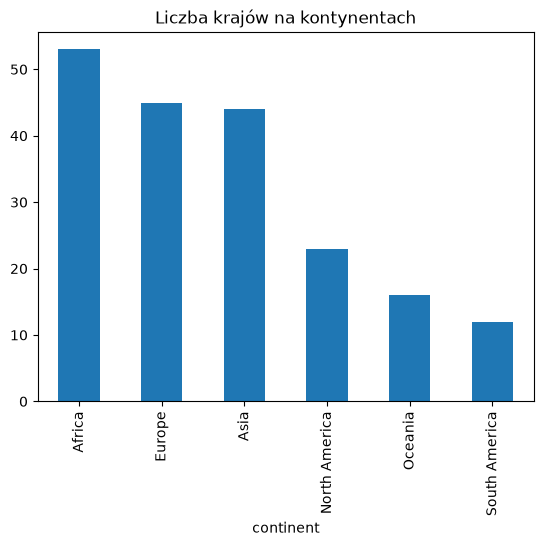

In [99]:
drinks['continent'].value_counts().plot(kind='bar', title='Liczba krajów na kontynentach');

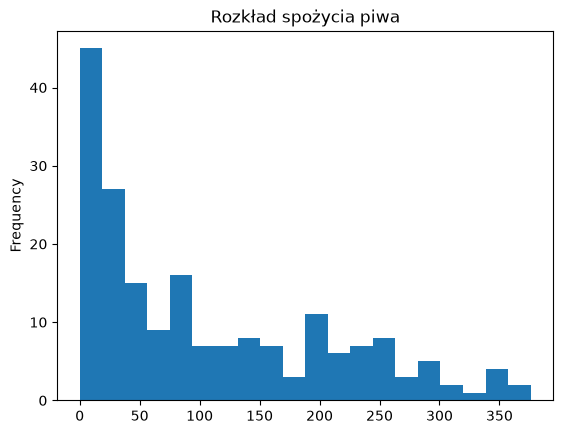

In [100]:
drinks['beer_servings'].plot(kind='hist', bins=20, title='Rozkład spożycia piwa');

## 4. Selekcja: kolumny, wiersze, filtrowanie

`DataFrame` łączy cechy słownika i tablicy 2D. Dostęp do danych ma kilka wzorców:

| Cel | Zapis |
|---|---|
| jedna kolumna (Series) | `df['kolumna']` |
| kilka kolumn (DataFrame) | `df[['kol1', 'kol2']]` |
| wiersze i kolumny po **etykietach** | `df.loc[wiersze, kolumny]` |
| wiersze i kolumny po **pozycjach** | `df.iloc[wiersze, kolumny]` |
| wiersze spełniające warunek | `df[warunek]` lub `df.loc[warunek, kolumny]` |

### Kolumny

In [101]:
drinks['country']

0      Afghanistan
1          Albania
2          Algeria
3          Andorra
4           Angola
          ...     
188      Venezuela
189        Vietnam
190          Yemen
191         Zambia
192       Zimbabwe
Name: country, Length: 193, dtype: str

In [102]:
drinks[['country', 'continent']]

,country,continent
0,Afghanistan,Asia
1,Albania,Europe
2,Algeria,Africa
3,Andorra,Europe
4,Angola,Africa
...,...,...
188,Venezuela,South America
189,Vietnam,Asia
190,Yemen,Asia
191,Zambia,Africa


### `loc` i `iloc` w ramce danych

In [103]:
drinks.loc[0]                  # wiersz o etykiecie 0 (jako Series)

country                         Afghanistan
beer_servings                             0
spirit_servings                           0
wine_servings                             0
total_litres_of_pure_alcohol            0.0
continent                              Asia
Name: 0, dtype: object

In [104]:
drinks.loc[0, 'country']       # pojedyncza komórka

'Afghanistan'

In [105]:
drinks.loc[:, 'country']       # cała kolumna

0      Afghanistan
1          Albania
2          Algeria
3          Andorra
4           Angola
          ...     
188      Venezuela
189        Vietnam
190          Yemen
191         Zambia
192       Zimbabwe
Name: country, Length: 193, dtype: str

In [106]:
drinks.iloc[:, 0]              # to samo, po pozycji kolumny

0      Afghanistan
1          Albania
2          Algeria
3          Andorra
4           Angola
          ...     
188      Venezuela
189        Vietnam
190          Yemen
191         Zambia
192       Zimbabwe
Name: country, Length: 193, dtype: str

In [107]:
drinks.iloc[:3, :2]            # 3 pierwsze wiersze, 2 pierwsze kolumny (prawy koniec wykluczony)

,country,beer_servings
0,Afghanistan,0
1,Albania,89
2,Algeria,25


Dla indeksu tekstowego różnica między `loc` i `iloc` jest wyraźniejsza. Ustawmy kraj jako indeks:

In [108]:
napoje = drinks.set_index('country')
napoje.head(3)

,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
country,,,,,
Afghanistan,0,0,0,0.0,Asia
Albania,89,132,54,4.9,Europe
Algeria,25,0,14,0.7,Africa


In [109]:
napoje.loc['Poland']                    # wiersz po etykiecie

beer_servings                      343
spirit_servings                    215
wine_servings                       56
total_litres_of_pure_alcohol      10.9
continent                       Europe
Name: Poland, dtype: object

In [110]:
napoje.loc['Poland', 'beer_servings']

np.int64(343)

In [111]:
napoje.loc[['Poland', 'Germany', 'France'], ['beer_servings', 'wine_servings']]    # listy etykiet

,beer_servings,wine_servings
country,,
Poland,343,56
Germany,346,175
France,127,370


In [112]:
napoje.loc['Poland':'Portugal', 'beer_servings':'wine_servings']    # wycinki etykiet: OBA końce włączone

,beer_servings,spirit_servings,wine_servings
country,,,
Poland,343,215,56
Portugal,194,67,339


In [113]:
napoje.iloc[135:138, 0:3]               # wycinki pozycji: prawy koniec wykluczony

,beer_servings,spirit_servings,wine_servings
country,,,
Poland,343,215,56
Portugal,194,67,339
Qatar,1,42,7


### Filtrowanie wierszy: maski logiczne

Warunek na kolumnie daje serię `True`/`False` (maskę). Użyta w nawiasach `[]` zostawia tylko wiersze z `True`. Warunki łączymy operatorami `&` (i), `|` (lub), `~` (negacja) – **każdy warunek w nawiasach**.

In [114]:
(drinks['continent'] == 'Europe').head()     # maska

0    False
1     True
2    False
3     True
4    False
Name: continent, dtype: bool

In [115]:
europa = drinks[drinks['continent'] == 'Europe']
europa.head()

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
1,Albania,89,132,54,4.9,Europe
3,Andorra,245,138,312,12.4,Europe
7,Armenia,21,179,11,3.8,Europe
9,Austria,279,75,191,9.7,Europe
10,Azerbaijan,21,46,5,1.3,Europe


In [116]:
europa[europa['beer_servings'] >= 300]

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
45,Czech Republic,361,170,134,11.8,Europe
65,Germany,346,117,175,11.3,Europe
81,Ireland,313,118,165,11.4,Europe
98,Lithuania,343,244,56,12.9,Europe
135,Poland,343,215,56,10.9,Europe


In [117]:
drinks[(drinks['continent'] == 'Europe') & (drinks['wine_servings'] > 200)]

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
3,Andorra,245,138,312,12.4,Europe
16,Belgium,295,84,212,10.5,Europe
42,Croatia,230,87,254,10.2,Europe
48,Denmark,224,81,278,10.4,Europe
61,France,127,151,370,11.8,Europe
67,Greece,133,112,218,8.3,Europe
83,Italy,85,42,237,6.5,Europe
99,Luxembourg,236,133,271,11.4,Europe
136,Portugal,194,67,339,11.0,Europe
156,Slovenia,270,51,276,10.6,Europe


In [118]:
drinks[(drinks['beer_servings'] > 300) | (drinks['spirit_servings'] > 300)]

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
15,Belarus,142,373,42,14.4,Europe
45,Czech Republic,361,170,134,11.8,Europe
62,Gabon,347,98,59,8.9,Africa
65,Germany,346,117,175,11.3,Europe
68,Grenada,199,438,28,11.9,North America
72,Guyana,93,302,1,7.1,South America
73,Haiti,1,326,1,5.9,North America
81,Ireland,313,118,165,11.4,Europe
98,Lithuania,343,244,56,12.9,Europe
117,Namibia,376,3,1,6.8,Africa


In [119]:
drinks[~(drinks['continent'] == 'Europe')].head(3)    # negacja: wszystko poza Europą

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,Afghanistan,0,0,0,0.0,Asia
2,Algeria,25,0,14,0.7,Africa
4,Angola,217,57,45,5.9,Africa


Przydatne skróty: `isin()` (wartość z listy), `between()` (przedział włącznie), `str.contains()` (fragment tekstu):

In [120]:
drinks[drinks['continent'].isin(['Europe', 'Oceania'])].head(3)

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
1,Albania,89,132,54,4.9,Europe
3,Andorra,245,138,312,12.4,Europe
7,Armenia,21,179,11,3.8,Europe


In [121]:
drinks[drinks['total_litres_of_pure_alcohol'].between(10, 11)]

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
8,Australia,261,72,212,10.4,Oceania
16,Belgium,295,84,212,10.5,Europe
25,Bulgaria,231,252,94,10.3,Europe
42,Croatia,230,87,254,10.2,Europe
48,Denmark,224,81,278,10.4,Europe
60,Finland,263,133,97,10.0,Europe
93,Latvia,281,216,62,10.5,Europe
135,Poland,343,215,56,10.9,Europe
136,Portugal,194,67,339,11.0,Europe
140,Romania,297,122,167,10.4,Europe


In [122]:
drinks[drinks['country'].str.contains('land')]       # nazwy zawierające „land”

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
40,Cook Islands,0,254,74,5.9,Oceania
60,Finland,263,133,97,10.0,Europe
76,Iceland,233,61,78,6.6,Europe
81,Ireland,313,118,165,11.4,Europe
106,Marshall Islands,0,0,0,0.0,Oceania
120,Netherlands,251,88,190,9.4,Europe
121,New Zealand,203,79,175,9.3,Oceania
135,Poland,343,215,56,10.9,Europe
157,Solomon Islands,56,11,1,1.2,Oceania
164,Swaziland,90,2,2,4.7,Africa


Liczenie spełniających warunek: `True` to 1, więc `sum()` zlicza, a `mean()` daje udział:

In [123]:
print((drinks['beer_servings'] > 300).sum())          # liczba krajów
print((drinks['beer_servings'] > 300).mean().round(3))   # udział krajów

9
0.047


### Wybór wierszy i kolumn jednocześnie

`loc[warunek, kolumny]` pozwala od razu wybrać wiersze **i** kolumny:

In [124]:
drinks.loc[drinks['beer_servings'] > 300, ['country', 'beer_servings']]

,country,beer_servings
45,Czech Republic,361
62,Gabon,347
65,Germany,346
81,Ireland,313
98,Lithuania,343
117,Namibia,376
129,Palau,306
135,Poland,343
188,Venezuela,333


### Metoda `query()`

Alternatywa dla nawiasów `[]`. Warunek zapisujemy jako tekst, składnią podobną do `WHERE` w SQL; zmienne Pythona wskazujemy znakiem `@`:

In [125]:
drinks.query("beer_servings >= 300")

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
45,Czech Republic,361,170,134,11.8,Europe
62,Gabon,347,98,59,8.9,Africa
65,Germany,346,117,175,11.3,Europe
81,Ireland,313,118,165,11.4,Europe
98,Lithuania,343,244,56,12.9,Europe
117,Namibia,376,3,1,6.8,Africa
129,Palau,306,63,23,6.9,Oceania
135,Poland,343,215,56,10.9,Europe
188,Venezuela,333,100,3,7.7,South America


In [126]:
prog = 250
drinks.query("continent == 'Europe' and beer_servings > @prog")

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
9,Austria,279,75,191,9.7,Europe
16,Belgium,295,84,212,10.5,Europe
45,Czech Republic,361,170,134,11.8,Europe
60,Finland,263,133,97,10.0,Europe
65,Germany,346,117,175,11.3,Europe
81,Ireland,313,118,165,11.4,Europe
93,Latvia,281,216,62,10.5,Europe
98,Lithuania,343,244,56,12.9,Europe
120,Netherlands,251,88,190,9.4,Europe
135,Poland,343,215,56,10.9,Europe


### Zmiana wartości w wybranych komórkach

Przypisanie do `loc[warunek, kolumna]` zmienia wybrane komórki **w tej samej tabeli**. Robimy to na kopii (`copy()`), żeby nie zepsuć oryginału:

In [127]:
kopia = drinks.copy()
kopia['poziom'] = 'niski'
kopia.loc[kopia['total_litres_of_pure_alcohol'] > 8, 'poziom'] = 'wysoki'
kopia[['country', 'total_litres_of_pure_alcohol', 'poziom']].sort_values('total_litres_of_pure_alcohol').tail(5)

,country,total_litres_of_pure_alcohol,poziom
45,Czech Republic,11.8,wysoki
68,Grenada,11.9,wysoki
3,Andorra,12.4,wysoki
98,Lithuania,12.9,wysoki
15,Belarus,14.4,wysoki


In [128]:
kopia['poziom'].value_counts()

poziom
niski     150
wysoki     43
Name: count, dtype: int64

---

### Czas na zadania 11–20

Otwórz notatnik `Zadania/11-20.ipynb` i rozwiąż ćwiczenia 11–20 (zakres: wczytywanie, pierwszy rzut oka na dane, selekcja i filtrowanie, sekcje 3 i 4).

## 5. Tworzenie i przekształcanie kolumn

W analizie danych i ML często tworzymy **nowe cechy** na podstawie istniejących (tzw. *feature engineering*): sumy, proporcje, kategorie, wartości wyciągnięte z tekstu. Pandas robi to wektorowo – bez pisania pętli.

### Arytmetyka na kolumnach

In [129]:
napoje = drinks.copy()
napoje['porcje_razem'] = napoje['beer_servings'] + napoje['spirit_servings'] + napoje['wine_servings']
napoje['udział_piwa'] = (napoje['beer_servings'] / napoje['porcje_razem']).round(2)
napoje.head()

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent,porcje_razem,udział_piwa
0,Afghanistan,0,0,0,0.0,Asia,0,NaN
1,Albania,89,132,54,4.9,Europe,275,0.32
2,Algeria,25,0,14,0.7,Africa,39,0.64
3,Andorra,245,138,312,12.4,Europe,695,0.35
4,Angola,217,57,45,5.9,Africa,319,0.68


Dzielenie przez zero daje `NaN` (kraje, w których w ogóle nie pije się alkoholu) – to ważne przy czyszczeniu danych:

In [130]:
napoje[napoje['porcje_razem'] == 0].head(3)

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent,porcje_razem,udział_piwa
0,Afghanistan,0,0,0,0.0,Asia,0,NaN
13,Bangladesh,0,0,0,0.0,Asia,0,NaN
46,North Korea,0,0,0,0.0,Asia,0,NaN


In [131]:
napoje['beer_servings'].astype(float).head(3)     # zmiana typu kolumny

0     0.0
1    89.0
2    25.0
Name: beer_servings, dtype: float64

### Warunki: `np.where`, `clip`

`np.where(warunek, wartość_gdy_prawda, wartość_gdy_fałsz)` buduje kolumnę na podstawie warunku (jak `IF` w Excelu). `clip()` przycina wartości do przedziału.

In [132]:
napoje['piwosz'] = np.where(napoje['beer_servings'] > 200, 'tak', 'nie')
napoje['piwosz'].value_counts()

piwosz
nie    153
tak     40
Name: count, dtype: int64

In [133]:
napoje['beer_servings'].clip(lower=50, upper=300).describe()[['min', 'max']]

min     50.0
max    300.0
Name: beer_servings, dtype: float64

### Mapowanie i zamiana wartości: `map`, `replace`

`map()` zamienia wartości kolumny według **słownika** lub funkcji. Wartości, których nie ma w słowniku, stają się `NaN`. `replace()` zamienia tylko wskazane wartości, resztę zostawia.

In [134]:
nazwy_pl = {'Europe': 'Europa', 'Asia': 'Azja', 'Africa': 'Afryka', 'Oceania': 'Oceania'}
napoje['kontynent'] = napoje['continent'].map(nazwy_pl)    # brakuje Ameryk -> NaN
napoje[['continent', 'kontynent']].drop_duplicates()

,continent,kontynent
0,Asia,Azja
1,Europe,Europa
2,Africa,Afryka
5,North America,NaN
6,South America,NaN
8,Oceania,Oceania


In [135]:
napoje['continent'].replace({'Europe': 'Europa'}).value_counts().head(3)    # pozostałe wartości bez zmian

continent
Africa    53
Europa    45
Asia      44
Name: count, dtype: int64

### `apply` i `map` z funkcją

- `Series.map(funkcja)` – stosuje funkcję do **każdego elementu** serii,
- `Series.apply(funkcja)` – podobnie, ale bardziej ogólnie,
- `DataFrame.apply(funkcja, axis=1)` – stosuje funkcję do **każdego wiersza** (funkcja dostaje cały wiersz).

Funkcje własne (lub `lambda`) są elastyczne, ale **wolne** na dużych danych. Jeśli da się zapisać operację wektorowo (`+`, `np.where`, metody `.str`), robimy to wektorowo.

In [136]:
def kategoria_alkoholu(litry):
    if litry <= 3:
        return 'małe'
    elif litry <= 9:
        return 'średnie'
    return 'duże'

napoje['spożycie'] = napoje['total_litres_of_pure_alcohol'].map(kategoria_alkoholu)
napoje['spożycie'].value_counts()

spożycie
małe       84
średnie    75
duże       34
Name: count, dtype: int64

In [137]:
napoje.apply(lambda wiersz: wiersz['beer_servings'] > wiersz['wine_servings'], axis=1).head(3)    # funkcja dla każdego wiersza

0    False
1     True
2     True
dtype: bool

Przedziały liczbowe najszybciej tworzymy funkcją **`pd.cut()`** (własne granice) lub **`pd.qcut()`** (przedziały o równej liczności, czyli kwantyle):

In [138]:
napoje['spożycie2'] = pd.cut(napoje['total_litres_of_pure_alcohol'],
                             bins=[-1, 3, 9, 20],
                             labels=['małe', 'średnie', 'duże'])
napoje['spożycie2'].value_counts()

spożycie2
małe       84
średnie    75
duże       34
Name: count, dtype: int64

In [139]:
pd.qcut(napoje['beer_servings'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4']).value_counts().sort_index()   # 4 równoliczne grupy

beer_servings
Q1    49
Q2    49
Q3    47
Q4    48
Name: count, dtype: int64

### Tekst w kolumnach: akcesor `.str`

Metody tekstowe (`lower`, `strip`, `split`, `replace`, `contains`…) są dostępne w akcesorze `.str` i działają na całej kolumnie. W prawdziwych danych liczby bywają zapisane jako tekst z jednostką (np. `'998 CC'`) – trzeba je „oczyścić” i zamienić na liczby.

In [140]:
auta = pd.DataFrame({'model': ['Maruti Wagon R LXI CNG', 'Hyundai Creta 1.6 CRDi', 'Honda Jazz V', 'Hyundai i20'],
                     'silnik': ['998 CC', '1582 CC', '1199 CC', '1197 CC'],
                     'moc': ['58.16 bhp', '126.2 bhp', 'null bhp', '81.83 bhp'],
                     'cena': [1.75, 12.5, 4.5, 3.5]})
auta

,model,silnik,moc,cena
0,Maruti Wagon R LXI CNG,998 CC,58.16 bhp,1.75
1,Hyundai Creta 1.6 CRDi,1582 CC,126.2 bhp,12.50
2,Honda Jazz V,1199 CC,null bhp,4.50
3,Hyundai i20,1197 CC,81.83 bhp,3.50


In [141]:
auta['model'].str.upper()

0    MARUTI WAGON R LXI CNG
1    HYUNDAI CRETA 1.6 CRDI
2              HONDA JAZZ V
3               HYUNDAI I20
Name: model, dtype: str

In [142]:
auta['model'].str.split().str[0]        # pierwsze słowo = marka

0     Maruti
1    Hyundai
2      Honda
3    Hyundai
Name: model, dtype: object

In [143]:
auta['model'].str.contains('Hyundai')

0    False
1     True
2    False
3     True
Name: model, dtype: bool

In [144]:
auta['model'].str.len()

0    22
1    22
2    12
3    11
Name: model, dtype: int64

In [145]:
auta['model'].str.split(expand=True)    # podział na osobne kolumny

,0,1,2,3,4
0,Maruti,Wagon,R,LXI,CNG
1,Hyundai,Creta,1.6,CRDi,NaN
2,Honda,Jazz,V,NaN,NaN
3,Hyundai,i20,NaN,NaN,NaN


Zamiana tekstu `'998 CC'` na liczbę: usuwamy jednostkę, potem zmieniamy typ.

In [146]:
auta['silnik_cc'] = auta['silnik'].str.replace(' CC', '').astype(int)
auta[['silnik', 'silnik_cc']]

,silnik,silnik_cc
0,998 CC,998
1,1582 CC,1582
2,1199 CC,1199
3,1197 CC,1197


In [147]:
auta['silnik_cc'] = auta['silnik'].str.extract(r'(\d+)')[0].astype(int)     # inny sposób: wyrażenie regularne
auta['silnik_cc']

0     998
1    1582
2    1199
3    1197
Name: silnik_cc, dtype: int64

Kolumna `moc` zawiera napis `null bhp` zamiast liczby. `astype(float)` zgłosiłoby błąd. Funkcja **`pd.to_numeric(..., errors='coerce')`** zamienia to, co nie jest liczbą, na `NaN`:

In [148]:
try:
    auta['moc'].str.replace(' bhp', '').astype(float)
except ValueError as e:
    print("ValueError:", e)

ValueError: could not convert string to float: 'null'


In [149]:
auta['moc_bhp'] = pd.to_numeric(auta['moc'].str.replace(' bhp', ''), errors='coerce')
auta[['moc', 'moc_bhp']]

,moc,moc_bhp
0,58.16 bhp,58.16
1,126.2 bhp,126.20
2,null bhp,NaN
3,81.83 bhp,81.83


### Sortowanie, rankingi, sumy skumulowane

In [150]:
napoje.sort_values(by='total_litres_of_pure_alcohol', ascending=False)[['country', 'total_litres_of_pure_alcohol']].head(5)

,country,total_litres_of_pure_alcohol
15,Belarus,14.4
98,Lithuania,12.9
3,Andorra,12.4
68,Grenada,11.9
45,Czech Republic,11.8


In [151]:
napoje.sort_values(by=['continent', 'beer_servings'], ascending=[True, False])[['continent', 'country', 'beer_servings']].head(5)   # po kilku kolumnach

,continent,country,beer_servings
117,Africa,Namibia,376
62,Africa,Gabon,347
159,Africa,South Africa,225
4,Africa,Angola,217
22,Africa,Botswana,173


In [152]:
napoje.nlargest(3, 'wine_servings')[['country', 'wine_servings']]      # n największych

,country,wine_servings
61,France,370
136,Portugal,339
3,Andorra,312


In [153]:
napoje['beer_servings'].head(5).cumsum()     # suma skumulowana (też: cumprod, cummax)

0      0
1     89
2    114
3    359
4    576
Name: beer_servings, dtype: int64

In [154]:
napoje['beer_servings'].rank(ascending=False).head(3)

0    186.0
1     86.0
2    136.5
Name: beer_servings, dtype: float64

Duplikaty wierszy znajdziemy metodą `duplicated()` i usuwamy `drop_duplicates()`:

In [155]:
duplikaty = pd.DataFrame({'klient': ['A', 'B', 'A', 'C', 'B'], 'miasto': ['Łódź', 'Gdańsk', 'Łódź', 'Kraków', 'Poznań']})
duplikaty.duplicated().sum()     # liczba zduplikowanych wierszy (wiersz identyczny z wcześniejszym)

np.int64(1)

In [156]:
duplikaty.drop_duplicates()

,klient,miasto
0,A,Łódź
1,B,Gdańsk
3,C,Kraków
4,B,Poznań


In [157]:
duplikaty.drop_duplicates(subset='klient')      # duplikaty tylko według wybranej kolumny

,klient,miasto
0,A,Łódź
1,B,Gdańsk
3,C,Kraków


## 6. Braki danych

Prawdziwe dane prawie zawsze mają braki. W Pandas brak jest oznaczany jako `NaN` (*Not a Number*). Większość modeli ML **nie przyjmuje** `NaN`, więc musimy z nim coś zrobić: usunąć lub uzupełnić (*imputacja*). Dziś poznajemy narzędzia Pandas; imputację przygotowaną pod ML (`SimpleImputer`) zobaczymy w notatnikach o scikit-learn.

In [158]:
df = pd.DataFrame({'A': [1, 2, np.nan, 4],
                   'B': [5, np.nan, np.nan, 8],
                   'C': [1, 2, 3, 4]})
df

,A,B,C
0,1.0,5.0,1
1,2.0,NaN,2
2,NaN,NaN,3
3,4.0,8.0,4


**Wykrywanie braków.** `isna()` zwraca maskę `True` dla braków, a `sum()` liczy je w każdej kolumnie:

In [159]:
df.isna()

,A,B,C
0,False,False,False
1,False,True,False
2,True,True,False
3,False,False,False


In [160]:
df.isna().sum()      # liczba braków w kolumnach

A    1
B    2
C    0
dtype: int64

In [161]:
df.isna().mean().round(2)     # udział braków w kolumnach

A    0.25
B    0.50
C    0.00
dtype: float64

In [162]:
df.isna().any(axis=1).sum()   # ile wierszy ma przynajmniej jeden brak

np.int64(2)

> **Uwaga.** `NaN` nie jest równe samemu sobie, więc `df['A'] == np.nan` zawsze daje `False`. Braki wykrywamy tylko przez `isna()` / `notna()`.

In [163]:
print((df['A'] == np.nan).sum())    # 0 - porównanie z NaN nic nie znajduje
print(df['A'].isna().sum())       # 1 - poprawne wykrycie braku

0
1


**Usuwanie braków** – `dropna()` (kolumn: `axis=1`; próg: `thresh`; tylko wybrane kolumny: `subset`):

In [164]:
df.dropna()                  # usuń wiersze z jakimkolwiek brakiem

,A,B,C
0,1.0,5.0,1
3,4.0,8.0,4


In [165]:
df.dropna(axis=1)            # usuń kolumny z brakiem

,C
0,1
1,2
2,3
3,4


In [166]:
df.dropna(thresh=2)          # zostaw wiersze mające co najmniej 2 wartości niepuste

,A,B,C
0,1.0,5.0,1
1,2.0,NaN,2
3,4.0,8.0,4


In [167]:
df.dropna(subset=['A'])      # patrz tylko na kolumnę A

,A,B,C
0,1.0,5.0,1
1,2.0,NaN,2
3,4.0,8.0,4


**Uzupełnianie braków** – `fillna()`:

In [168]:
df.fillna(0)

,A,B,C
0,1.0,5.0,1
1,2.0,0.0,2
2,0.0,0.0,3
3,4.0,8.0,4


In [169]:
df.fillna({'A': df['A'].mean(), 'B': df['B'].median()})   # różne wartości dla różnych kolumn

,A,B,C
0,1.000000,5.0,1
1,2.000000,6.5,2
2,2.333333,6.5,3
3,4.000000,8.0,4


In [170]:
df['A'] = df['A'].fillna(df['A'].mean())     # uzupełnienie jednej kolumny jej średnią i przypisanie z powrotem
df

,A,B,C
0,1.000000,5.0,1
1,2.000000,NaN,2
2,2.333333,NaN,3
3,4.000000,8.0,4


Dla danych uporządkowanych w czasie braki można uzupełniać poprzednią (`ffill`) lub następną (`bfill`) wartością albo interpolować:

In [171]:
temperatura = pd.Series([20.0, np.nan, np.nan, 23.0, np.nan, 25.0])
pd.DataFrame({'dane': temperatura,
              'ffill': temperatura.ffill(),
              'bfill': temperatura.bfill(),
              'interpolacja': temperatura.interpolate()})

,dane,ffill,bfill,interpolacja
0,20.0,20.0,20.0,20.0
1,NaN,20.0,23.0,21.0
2,NaN,20.0,23.0,22.0
3,23.0,23.0,23.0,23.0
4,NaN,23.0,25.0,24.0
5,25.0,25.0,25.0,25.0


**Braki ukryte pod inną postacią.** Czasem brak jest zapisany jako `'null'`, `'-'`, `'brak'` itp. – Pandas nie rozpozna go sam. Zamieniamy je na `NaN` przy wczytywaniu (`na_values=[...]`) albo później (`replace`, `to_numeric(errors='coerce')`), jak w przykładzie z mocą silnika:

In [172]:
auta['moc_bhp'].isna().sum()

np.int64(1)

In [173]:
auta.dropna(subset=['moc_bhp'])

,model,silnik,moc,cena,silnik_cc,moc_bhp
0,Maruti Wagon R LXI CNG,998 CC,58.16 bhp,1.75,998,58.16
1,Hyundai Creta 1.6 CRDi,1582 CC,126.2 bhp,12.50,1582,126.20
3,Hyundai i20,1197 CC,81.83 bhp,3.50,1197,81.83


**Co wybrać?** Usunięcie wierszy jest proste, ale tracimy dane (przy dużym odsetku braków model uczy się na małej próbce). Uzupełnienie średnią lub medianą zachowuje wiersze, ale „spłaszcza” rozkład. Zawsze sprawdź, **ile** braków jest i **dlaczego** powstały. Imputację do ML robimy tak, by statystyki liczyć tylko ze zbioru treningowego – o tym w notatnikach o scikit-learn.

## 7. Grupowanie (`groupby`)

`groupby` realizuje schemat **podziel – zastosuj – połącz** (*split-apply-combine*): dzieli tabelę na grupy według wartości kolumny, liczy statystykę osobno w każdej grupie i składa wyniki. To odpowiednik `GROUP BY` w SQL i tabeli przestawnej w Excelu.

In [174]:
sprzedaż = pd.DataFrame({'Firma': ['GOOG', 'GOOG', 'MSFT', 'MSFT', 'FB', 'FB'],
                         'Osoba': ['Sam', 'Charlie', 'Amy', 'Vanessa', 'Carl', 'Sarah'],
                         'Sprzedaż': [200, 120, 340, 124, 243, 350]})
sprzedaż

,Firma,Osoba,Sprzedaż
0,GOOG,Sam,200
1,GOOG,Charlie,120
2,MSFT,Amy,340
3,MSFT,Vanessa,124
4,FB,Carl,243
5,FB,Sarah,350


In [175]:
sprzedaż.groupby('Firma')['Sprzedaż'].mean()      # średnia sprzedaż w każdej firmie

Firma
FB      296.5
GOOG    160.0
MSFT    232.0
Name: Sprzedaż, dtype: float64

> **Pandas 3.** Agregacja `mean()` na wszystkich kolumnach wymaga, by były liczbowe. Kolumna tekstowa (`Osoba`) zgłosi błąd `TypeError`, dlatego wskazujemy kolumnę (`['Sprzedaż']`) albo dodajemy `numeric_only=True`.

In [176]:
try:
    sprzedaż.groupby('Firma').mean()
except TypeError as e:
    print("TypeError:", e)
sprzedaż.groupby('Firma').mean(numeric_only=True)

TypeError: dtype 'str' does not support operation 'mean'


,Sprzedaż
Firma,
FB,296.5
GOOG,160.0
MSFT,232.0


Grupowanie zapisujemy do zmiennej i wykonujemy różne agregacje:

In [177]:
wg_firmy = sprzedaż.groupby('Firma')
wg_firmy['Sprzedaż'].sum()

Firma
FB      593
GOOG    320
MSFT    464
Name: Sprzedaż, dtype: int64

In [178]:
wg_firmy.size()          # liczba wierszy w grupie

Firma
FB      2
GOOG    2
MSFT    2
dtype: int64

In [179]:
wg_firmy['Sprzedaż'].agg(['count', 'mean', 'std', 'min', 'max'])    # wiele statystyk naraz

,count,mean,std,min,max
Firma,,,,,
FB,2,296.5,75.660426,243,350
GOOG,2,160.0,56.568542,120,200
MSFT,2,232.0,152.735065,124,340


In [180]:
wg_firmy['Sprzedaż'].describe()

,count,mean,std,min,25%,50%,75%,max
Firma,,,,,,,,
FB,2.0,296.5,75.660426,243.0,269.75,296.5,323.25,350.0
GOOG,2.0,160.0,56.568542,120.0,140.00,160.0,180.00,200.0
MSFT,2.0,232.0,152.735065,124.0,178.00,232.0,286.00,340.0


**Nazwane agregacje** pozwalają od razu nadać nazwy kolumnom wyniku (`nazwa=('kolumna', 'funkcja')`), a `reset_index()` zamienia klucz grupowania z powrotem w zwykłą kolumnę:

In [181]:
sprzedaż.groupby('Firma').agg(liczba=('Sprzedaż', 'count'),
                              średnia=('Sprzedaż', 'mean'),
                              maksimum=('Sprzedaż', 'max')).reset_index()

,Firma,liczba,średnia,maksimum
0,FB,2,296.5,350
1,GOOG,2,160.0,200
2,MSFT,2,232.0,340


Przykład na danych o alkoholu: średnie spożycie według kontynentów, posortowane:

In [182]:
drinks.groupby('continent')['total_litres_of_pure_alcohol'].mean().sort_values(ascending=False).round(2)

continent
Europe           8.62
South America    6.31
North America    6.00
Oceania          3.38
Africa           3.01
Asia             2.17
Name: total_litres_of_pure_alcohol, dtype: float64

In [183]:
drinks.groupby('continent')[['beer_servings', 'spirit_servings', 'wine_servings']].mean().round(0)

,beer_servings,spirit_servings,wine_servings
continent,,,
Africa,61.0,16.0,16.0
Asia,37.0,61.0,9.0
Europe,194.0,133.0,142.0
North America,145.0,166.0,25.0
Oceania,90.0,58.0,36.0
South America,175.0,115.0,62.0


Można grupować po **kilku kolumnach** naraz (wynik ma wtedy indeks wielopoziomowy):

In [184]:
napoje.groupby(['continent', 'piwosz'])['country'].count()

continent      piwosz
Africa         nie       49
               tak        4
Asia           nie       43
               tak        1
Europe         nie       21
               tak       24
North America  nie       18
               tak        5
Oceania        nie       13
               tak        3
South America  nie        9
               tak        3
Name: country, dtype: int64

In [185]:
napoje.groupby(['continent', 'piwosz'])['country'].count().unstack(fill_value=0)    # drugi klucz jako kolumny

piwosz,nie,tak
continent,,
Africa,49,4
Asia,43,1
Europe,21,24
North America,18,5
Oceania,13,3
South America,9,3


**`transform`** zwraca wynik o **tym samym kształcie** co oryginał (statystyka grupy przypisana do każdego wiersza) – wygodne do cech typu „odchylenie od średniej w grupie”:

In [186]:
sprzedaż['średnia_firmy'] = wg_firmy['Sprzedaż'].transform('mean')
sprzedaż['różnica'] = sprzedaż['Sprzedaż'] - sprzedaż['średnia_firmy']
sprzedaż

,Firma,Osoba,Sprzedaż,średnia_firmy,różnica
0,GOOG,Sam,200,160.0,40.0
1,GOOG,Charlie,120,160.0,-40.0
2,MSFT,Amy,340,232.0,108.0
3,MSFT,Vanessa,124,232.0,-108.0
4,FB,Carl,243,296.5,-53.5
5,FB,Sarah,350,296.5,53.5


**Tabela przestawna** (`pivot_table`) to wygodny skrót dla grupowania z podziałem na wiersze i kolumny, jak w Excelu:

In [187]:
pd.pivot_table(napoje, values='beer_servings', index='continent', columns='piwosz', aggfunc='mean').round(0)

piwosz,nie,tak
continent,,
Africa,43.0,291.0
Asia,32.0,247.0
Europe,106.0,270.0
North America,115.0,255.0
Oceania,51.0,257.0
South America,146.0,264.0


---

### Czas na zadania 21–30

Otwórz notatnik `Zadania/21-30.ipynb` i rozwiąż ćwiczenia 21–30 (zakres: nowe kolumny, `apply`/`map`, tekst, sortowanie, braki danych i grupowanie, sekcje 5–7).

## 8. Łączenie tabel: `concat`, `merge`, `join`

Dane rzadko leżą w jednej tabeli: klienci są w jednej, zamówienia w drugiej, produkty w trzeciej. Pandas oferuje trzy narzędzia:

| Narzędzie | Do czego | Analogia |
|---|---|---|
| `pd.concat` | **sklejanie** tabel pod sobą lub obok siebie | `UNION` |
| `pd.merge` | **złączanie** tabel po wspólnej kolumnie (kluczu) | `JOIN` w SQL |
| `df.join` | złączanie po **indeksie** | `JOIN` po indeksie |

### Sklejanie: `pd.concat`

In [188]:
styczeń = pd.DataFrame({'produkt': ['chleb', 'mleko', 'masło'], 'sprzedaż': [120, 200, 80]})
luty = pd.DataFrame({'produkt': ['chleb', 'mleko', 'ser'], 'sprzedaż': [130, 190, 60]})
display(styczeń, luty)

,produkt,sprzedaż
0,chleb,120
1,mleko,200
2,masło,80


,produkt,sprzedaż
0,chleb,130
1,mleko,190
2,ser,60


In [189]:
pd.concat([styczeń, luty])            # pod sobą (axis=0, domyślnie) - indeksy się powtarzają

,produkt,sprzedaż
0,chleb,120
1,mleko,200
2,masło,80
0,chleb,130
1,mleko,190
2,ser,60


In [190]:
pd.concat([styczeń, luty], ignore_index=True)       # nowy, ciągły indeks

,produkt,sprzedaż
0,chleb,120
1,mleko,200
2,masło,80
3,chleb,130
4,mleko,190
5,ser,60


In [191]:
pd.concat([styczeń, luty], keys=['styczeń', 'luty'])     # dodatkowy poziom indeksu z etykietą źródła

produkt  sprzedaż
styczeń 0   chleb       120
        1   mleko       200
        2   masło        80
luty    0   chleb       130
        1   mleko       190
        2     ser        60

In [192]:
pd.concat([styczeń, luty], axis=1)      # obok siebie (dopasowanie po indeksie)

,produkt,sprzedaż,produkt,sprzedaż
0,chleb,120,chleb,130
1,mleko,200,mleko,190
2,masło,80,ser,60


Jeśli kolumny się różnią, `concat` uzupełnia braki wartością `NaN`:

In [193]:
pd.concat([styczeń, pd.DataFrame({'produkt': ['jajka'], 'cena': [12.5]})], ignore_index=True)

,produkt,sprzedaż,cena
0,chleb,120.0,NaN
1,mleko,200.0,NaN
2,masło,80.0,NaN
3,jajka,NaN,12.5


### Złączanie po kluczu: `pd.merge`

Mamy tabelę klientów i tabelę zamówień. Klucz łączący to `id_klienta`.

In [194]:
klienci = pd.DataFrame({'id_klienta': [1, 2, 3, 4],
                        'imię': ['Anna', 'Piotr', 'Ewa', 'Marek'],
                        'miasto': ['Łódź', 'Gdańsk', 'Kraków', 'Łódź']})
zamówienia = pd.DataFrame({'id_zamówienia': [101, 102, 103, 104, 105],
                           'id_klienta': [1, 1, 3, 5, 2],
                           'kwota': [250, 100, 80, 500, 40]})
display(klienci, zamówienia)

,id_klienta,imię,miasto
0,1,Anna,Łódź
1,2,Piotr,Gdańsk
2,3,Ewa,Kraków
3,4,Marek,Łódź


,id_zamówienia,id_klienta,kwota
0,101,1,250
1,102,1,100
2,103,3,80
3,104,5,500
4,105,2,40


Klient 4 (Marek) nie złożył zamówienia, a zamówienie 104 dotyczy klienta 5, którego nie ma w tabeli klientów. Rodzaj złączenia (`how`) decyduje, co zrobić z takimi wierszami:

In [195]:
pd.merge(klienci, zamówienia, on='id_klienta', how='inner')    # tylko klucze występujące w obu tabelach

,id_klienta,imię,miasto,id_zamówienia,kwota
0,1,Anna,Łódź,101,250
1,3,Ewa,Kraków,103,80
2,1,Anna,Łódź,102,100
3,2,Piotr,Gdańsk,105,40


In [196]:
pd.merge(klienci, zamówienia, on='id_klienta', how='left')     # wszyscy klienci (także bez zamówień)

,id_klienta,imię,miasto,id_zamówienia,kwota
0,1,Anna,Łódź,101.0,250.0
1,1,Anna,Łódź,102.0,100.0
2,2,Piotr,Gdańsk,105.0,40.0
3,3,Ewa,Kraków,103.0,80.0
4,4,Marek,Łódź,NaN,NaN


In [197]:
pd.merge(klienci, zamówienia, on='id_klienta', how='right')    # wszystkie zamówienia

,id_klienta,imię,miasto,id_zamówienia,kwota
0,1,Anna,Łódź,101,250
1,1,Anna,Łódź,102,100
2,3,Ewa,Kraków,103,80
3,5,NaN,NaN,104,500
4,2,Piotr,Gdańsk,105,40


In [198]:
pd.merge(klienci, zamówienia, on='id_klienta', how='outer', indicator=True)    # wszystko; _merge pokazuje źródło wiersza

,id_klienta,imię,miasto,id_zamówienia,kwota,_merge
0,1,Anna,Łódź,101.0,250.0,both
1,1,Anna,Łódź,102.0,100.0,both
2,2,Piotr,Gdańsk,105.0,40.0,both
3,3,Ewa,Kraków,103.0,80.0,both
4,4,Marek,Łódź,NaN,NaN,left_only
5,5,NaN,NaN,104.0,500.0,right_only


| `how` | wynik |
|---|---|
| `inner` | tylko wspólne klucze (domyślnie) |
| `left` | wszystkie wiersze lewej tabeli |
| `right` | wszystkie wiersze prawej tabeli |
| `outer` | wszystkie wiersze z obu tabel |

Gdy kolumny z kluczem nazywają się inaczej, używamy `left_on` i `right_on`. Gdy w obu tabelach są kolumny o tej samej nazwie (nie będące kluczem), Pandas dodaje przyrostki `_x`/`_y`, które możemy zmienić argumentem `suffixes`.

In [199]:
produkty = pd.DataFrame({'kod': ['A', 'B', 'C'], 'nazwa': ['Laptop', 'Mysz', 'Monitor'], 'cena': [3500, 80, 900]})
sprzedane = pd.DataFrame({'produkt_kod': ['A', 'C', 'C', 'B'], 'ilość': [1, 2, 1, 5], 'cena': [3400, 880, 900, 75]})
pd.merge(sprzedane, produkty, left_on='produkt_kod', right_on='kod', suffixes=('_sprzedaży', '_katalogowa'))

,produkt_kod,ilość,cena_sprzedaży,kod,nazwa,cena_katalogowa
0,A,1,3400,A,Laptop,3500
1,C,2,880,C,Monitor,900
2,C,1,900,C,Monitor,900
3,B,5,75,B,Mysz,80


Po złączeniu można od razu analizować: ile wydał każdy klient (tylko ci, którzy coś kupili)?

In [200]:
pd.merge(klienci, zamówienia, on='id_klienta').groupby('imię')['kwota'].sum()

imię
Anna     350
Ewa       80
Piotr     40
Name: kwota, dtype: int64

> **Uwaga na duplikaty kluczy.** Gdy klucz powtarza się w obu tabelach, `merge` zwraca **wszystkie kombinacje** wierszy – liczba wierszy może wzrosnąć nieoczekiwanie. Po złączeniu zawsze sprawdź `shape` i liczbę braków.

### Złączanie po indeksie: `join`

In [201]:
klienci_idx = klienci.set_index('id_klienta')
kwoty = zamówienia.groupby('id_klienta')[['kwota']].sum()
klienci_idx.join(kwoty, how='left')

,imię,miasto,kwota
id_klienta,,,
1,Anna,Łódź,350.0
2,Piotr,Gdańsk,40.0
3,Ewa,Kraków,80.0
4,Marek,Łódź,NaN


## 9. Daty i szeregi czasowe

Dane z datą (sprzedaż, logi, pomiary z czujników, notowania giełdowe) to bardzo częsty przypadek. Pandas ma wbudowane typy czasu (`Timestamp`, `Timedelta`) i bogaty zestaw operacji: wyciąganie części daty, resampling i okna kroczące.

### Znaczniki czasu i przedziały

In [202]:
pd.Timestamp('2024-03-15 14:30')

Timestamp('2024-03-15 14:30:00')

In [203]:
pd.Timestamp('2024-03-15') + pd.Timedelta(days=10, hours=6)      # data + odstęp czasu

Timestamp('2024-03-25 06:00:00')

In [204]:
pd.Timestamp('2024-12-24') - pd.Timestamp('2024-03-15')        # różnica dat to Timedelta

Timedelta('284 days 00:00:00')

**Zamiana tekstu na daty:** `pd.to_datetime()`. Różne zapisy daty rozpoznaje sama, ale dla formatów jednoznacznych warto podać `format`; `errors='coerce'` zamienia błędne daty na `NaT` (*Not a Time*, odpowiednik `NaN`).

In [205]:
teksty = pd.Series(['2024-01-15', '2024-02-20', '2024-03-05'])
daty = pd.to_datetime(teksty)
daty

0   2024-01-15
1   2024-02-20
2   2024-03-05
dtype: datetime64[us]

In [206]:
pd.to_datetime(pd.Series(['15.01.2024', '20.02.2024']), format='%d.%m.%Y')      # polski format dzień.miesiąc.rok

0   2024-01-15
1   2024-02-20
dtype: datetime64[us]

In [207]:
pd.to_datetime(pd.Series(['2024-01-15', 'brak', '2024-03-05']), errors='coerce')

0   2024-01-15
1          NaT
2   2024-03-05
dtype: datetime64[us]

Przy wczytywaniu pliku daty konwertujemy od razu argumentem `parse_dates`:

In [208]:
csv_tekst = '''data,temperatura
2024-07-01,24.5
2024-07-02,26.1
2024-07-03,23.8'''
pogoda = pd.read_csv(StringIO(csv_tekst), parse_dates=['data'])
pogoda.dtypes

data           datetime64[us]
temperatura           float64
dtype: object

**Zakresy dat:** `pd.date_range(start, periods=..., freq=...)`. Najczęstsze częstotliwości: `'D'` – dzień, `'h'` – godzina, `'W'` – tydzień, `'ME'` – koniec miesiąca, `'MS'` – początek miesiąca, `'QE'` – koniec kwartału.

In [209]:
pd.date_range('2024-01-01', periods=5, freq='D')

DatetimeIndex(['2024-01-01', '2024-01-02', '2024-01-03', '2024-01-04',
               '2024-01-05'],
              dtype='datetime64[us]', freq='D')

In [210]:
pd.date_range('2024-01-31', periods=4, freq='ME')

DatetimeIndex(['2024-01-31', '2024-02-29', '2024-03-31', '2024-04-30'], dtype='datetime64[us]', freq='ME')

### Akcesor `.dt`

Dla kolumn z datami (typ `datetime64`) dostępny jest akcesor `.dt` – działa jak `.str` dla tekstu.

In [211]:
rng = np.random.default_rng(42)                       # generator liczb losowych (jak w notatniku o NumPy)
dni = pd.date_range('2024-01-01', '2024-12-31', freq='D')
dzień_tygodnia = dni.dayofweek.to_numpy()             # 0 = poniedziałek ... 6 = niedziela
sprzedaż_dzienna = (100 + 0.2 * np.arange(len(dni))              # trend rosnący
                    + 30 * (dzień_tygodnia >= 5)                 # weekendy sprzedają więcej
                    + rng.normal(0, 10, len(dni)))               # szum losowy
sklep = pd.DataFrame({'data': dni, 'sprzedaż': sprzedaż_dzienna.round(1)})
sklep.head()

,data,sprzedaż
0,2024-01-01,103.0
1,2024-01-02,89.8
2,2024-01-03,107.9
3,2024-01-04,110.0
4,2024-01-05,81.3


In [212]:
sklep.dtypes

data        datetime64[us]
sprzedaż           float64
dtype: object

In [213]:
sklep['rok'] = sklep['data'].dt.year
sklep['miesiąc'] = sklep['data'].dt.month
sklep['dzień_tyg'] = sklep['data'].dt.day_name()          # nazwy po angielsku
sklep['kwartał'] = sklep['data'].dt.quarter
sklep['weekend'] = sklep['data'].dt.dayofweek >= 5
sklep.head(8)

,data,sprzedaż,rok,miesiąc,dzień_tyg,kwartał,weekend
0,2024-01-01,103.0,2024,1,Monday,1,False
1,2024-01-02,89.8,2024,1,Tuesday,1,False
2,2024-01-03,107.9,2024,1,Wednesday,1,False
3,2024-01-04,110.0,2024,1,Thursday,1,False
4,2024-01-05,81.3,2024,1,Friday,1,False
5,2024-01-06,118.0,2024,1,Saturday,1,True
6,2024-01-07,132.5,2024,1,Sunday,1,True
7,2024-01-08,98.2,2024,1,Monday,1,False


Wyciągnięte części daty to gotowe cechy do analizy (a później do modeli ML), np. średnia sprzedaż według dnia tygodnia:

In [214]:
sklep.groupby('dzień_tyg')['sprzedaż'].mean().round(1).sort_values(ascending=False)

dzień_tyg
Sunday       167.3
Saturday     166.3
Thursday     137.6
Tuesday      137.6
Monday       137.0
Wednesday    136.3
Friday       132.9
Name: sprzedaż, dtype: float64

In [215]:
(pd.Timestamp('2024-12-31') - sklep['data']).dt.days.head(3)     # liczba dni do końca roku

0    365
1    364
2    363
Name: data, dtype: int64

### Indeks czasowy i wycinanie po dacie

Gdy kolumna dat jest ustawiona jako indeks (`DatetimeIndex`), możemy wycinać po zapisie daty tekstem – także częściowym.

In [216]:
szereg = sklep.set_index('data')['sprzedaż']
szereg.loc['2024-03-01':'2024-03-05']

data
2024-03-01     95.2
2024-03-02    138.9
2024-03-03    144.0
2024-03-04    118.5
2024-03-05    119.9
Name: sprzedaż, dtype: float64

In [217]:
szereg.loc['2024-06'].describe().round(1)      # cały czerwiec

count     30.0
mean     143.3
std       14.9
min      124.0
25%      132.1
50%      140.0
75%      152.2
max      179.1
Name: sprzedaż, dtype: float64

### Resampling – zmiana częstotliwości

`resample()` działa jak `groupby` po okresach czasu: dzienne dane zamieniamy np. na tygodniowe lub miesięczne.

In [218]:
szereg.resample('ME').sum().round(0)       # suma miesięczna

data
2024-01-31    3460.0
2024-02-29    3414.0
2024-03-31    3841.0
2024-04-30    3775.0
2024-05-31    4178.0
2024-06-30    4300.0
2024-07-31    4555.0
2024-08-31    4723.0
2024-09-30    4880.0
2024-10-31    5111.0
2024-11-30    5266.0
2024-12-31    5559.0
Freq: ME, Name: sprzedaż, dtype: float64

In [219]:
szereg.resample('W').mean().round(1).head()    # średnia tygodniowa

data
2024-01-07    106.1
2024-01-14    113.0
2024-01-21    111.5
2024-01-28    114.1
2024-02-04    117.4
Freq: W-SUN, Name: sprzedaż, dtype: float64

In [220]:
szereg.resample('QE').agg(['sum', 'mean', 'max']).round(1)   # kilka agregacji naraz, kwartały

,sum,mean,max
data,,,
2024-03-31,10714.6,117.7,154.7
2024-06-30,12252.8,134.6,186.9
2024-09-30,14157.6,153.9,200.1
2024-12-31,15936.4,173.2,214.6


### Okna kroczące, przesunięcia i zmiany

- `rolling(n).mean()` – średnia krocząca z ostatnich `n` obserwacji (wygładza szum),
- `shift(n)` – przesunięcie wartości w czasie (wartość sprzed `n` okresów),
- `diff()` i `pct_change()` – zmiana bezwzględna i procentowa względem poprzedniego okresu.

In [221]:
wynik = pd.DataFrame({'sprzedaż': szereg,
                      'średnia_7dni': szereg.rolling(7).mean().round(1),
                      'wczoraj': szereg.shift(1),
                      'zmiana': szereg.diff().round(1),
                      'zmiana_%': (szereg.pct_change() * 100).round(1)})
wynik.head(10)

,sprzedaż,średnia_7dni,wczoraj,zmiana,zmiana_%
data,,,,,
2024-01-01,103.0,NaN,NaN,NaN,NaN
2024-01-02,89.8,NaN,103.0,-13.2,-12.8
2024-01-03,107.9,NaN,89.8,18.1,20.2
2024-01-04,110.0,NaN,107.9,2.1,1.9
2024-01-05,81.3,NaN,110.0,-28.7,-26.1
2024-01-06,118.0,NaN,81.3,36.7,45.1
2024-01-07,132.5,106.1,118.0,14.5,12.3
2024-01-08,98.2,105.4,132.5,-34.3,-25.9
2024-01-09,101.4,107.0,98.2,3.2,3.3


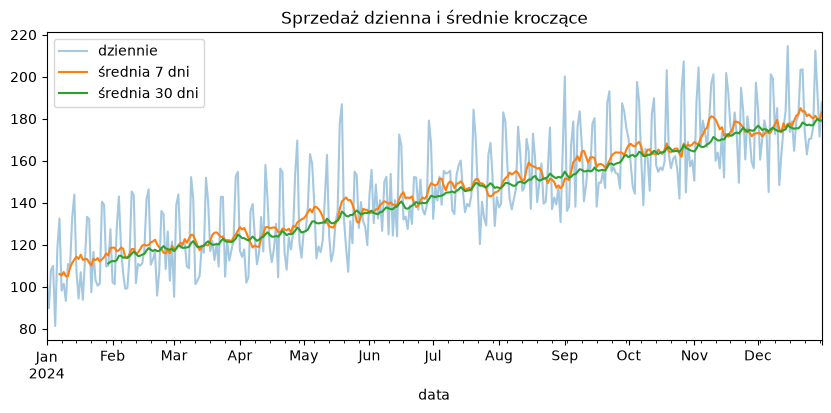

In [222]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
szereg.plot(ax=ax, alpha=0.4, label='dziennie')
szereg.rolling(7).mean().plot(ax=ax, label='średnia 7 dni')
szereg.rolling(30).mean().plot(ax=ax, label='średnia 30 dni')
ax.set_title('Sprzedaż dzienna i średnie kroczące')
ax.legend()
plt.show()

Przesunięcie `shift` jest też podstawą budowania cech dla ML na szeregach czasowych (np. „sprzedaż z poprzedniego dnia” jako zmienna objaśniająca).

Na koniec przykład z **prawdziwymi notowaniami giełdowymi**. Pobieramy je biblioteką `yfinance` (wymaga internetu); w razie problemu z siecią komórka wypisze komunikat, a reszta notatnika działa dalej.

In [223]:
try:
    import yfinance as yf
    akcje = yf.download('AAPL', start='2024-01-01', end='2024-06-30', auto_adjust=True, progress=False)
    akcje.columns = akcje.columns.get_level_values(0)       # wersje yfinance zwracają kolumny dwupoziomowe
    zamknięcie = akcje['Close']
    print(zamknięcie.resample('ME').last().round(2))
except Exception as e:
    print("Nie udało się pobrać notowań:", type(e).__name__)

Date
2024-01-31    182.18
2024-02-29    178.80
2024-03-31    169.63
2024-04-30    168.49
2024-05-31    190.43
2024-06-30    208.63
Freq: ME, Name: Close, dtype: float64


## 10. Pandas a SQL

Jeśli znasz SQL, większość operacji w Pandas będzie Ci znajoma. Poniżej ten sam zbiór pytań zadamy dwa razy: zapytaniem SQL do bazy SQLite (wbudowana w Pythona, działa w pamięci) i poleceniami Pandas. Użyjemy bazy 979 najlepiej ocenianych filmów z serwisu IMDb.

In [224]:
filmy = wczytaj_csv_z_internetu(URL + 'imdb_1000.csv')
filmy.head()

,star_rating,title,content_rating,genre,duration,actors_list
0,9.3,The Shawshank Redemption,R,Crime,142,"[u'Tim Robbins', u'Morgan Freeman', u'Bob Gunt..."
1,9.2,The Godfather,R,Crime,175,"[u'Marlon Brando', u'Al Pacino', u'James Caan']"
2,9.1,The Godfather: Part II,R,Crime,200,"[u'Al Pacino', u'Robert De Niro', u'Robert Duv..."
3,9.0,The Dark Knight,PG-13,Action,152,"[u'Christian Bale', u'Heath Ledger', u'Aaron E..."
4,8.9,Pulp Fiction,R,Crime,154,"[u'John Travolta', u'Uma Thurman', u'Samuel L...."


In [225]:
filmy.info()

<class 'pandas.DataFrame'>
RangeIndex: 979 entries, 0 to 978
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   star_rating     979 non-null    float64
 1   title           979 non-null    str    
 2   content_rating  976 non-null    str    
 3   genre           979 non-null    str    
 4   duration        979 non-null    int64  
 5   actors_list     979 non-null    str    
dtypes: float64(1), int64(1), str(4)
memory usage: 46.0 KB


| SQL | Pandas |
|---|---|
| `SELECT kol1, kol2` | `df[['kol1', 'kol2']]` |
| `WHERE warunek` | `df[maska]` lub `df.query('warunek')` |
| `ORDER BY kol DESC` | `df.sort_values('kol', ascending=False)` |
| `LIMIT n` | `df.head(n)` |
| `SELECT DISTINCT kol` | `df['kol'].unique()` |
| `COUNT(*)`, `AVG(kol)` | `len(df)`, `df['kol'].mean()` |
| `GROUP BY` | `df.groupby(...)` |
| `HAVING` | filtr na wyniku grupowania |
| `JOIN` | `pd.merge(...)` |
| `CASE WHEN` | `np.where(...)` |

In [226]:
import sqlite3

baza = sqlite3.connect(':memory:')                 # baza SQLite tylko w pamięci
filmy.to_sql('filmy', baza, index=False)           # zapisujemy DataFrame jako tabelę SQL

def sql(zapytanie):
    return pd.read_sql_query(zapytanie, baza)        # wynik zapytania SQL jako DataFrame

**Przykład 1: wybór kolumn, sortowanie, limit.**

In [227]:
sql('''
SELECT title, star_rating
FROM filmy
ORDER BY star_rating DESC
LIMIT 5
''')

,title,star_rating
0,The Shawshank Redemption,9.3
1,The Godfather,9.2
2,The Godfather: Part II,9.1
3,The Dark Knight,9.0
4,Pulp Fiction,8.9


In [228]:
filmy[['title', 'star_rating']].sort_values('star_rating', ascending=False).head(5)

,title,star_rating
0,The Shawshank Redemption,9.3
1,The Godfather,9.2
2,The Godfather: Part II,9.1
3,The Dark Knight,9.0
4,Pulp Fiction,8.9


**Przykład 2: filtrowanie.** W Pandas możemy użyć maski logicznej (z sekcji 4) albo metody `query()`, która przyjmuje warunek jako tekst, podobnie jak `WHERE`. Zmienne Pythona wskazujemy w niej znakiem `@`.

In [229]:
sql('''
SELECT title, duration, content_rating
FROM filmy
WHERE duration > 180 AND content_rating = 'R'
''')

,title,duration,content_rating
0,The Godfather: Part II,200,R
1,Schindler's List,195,R
2,The Green Mile,189,R
3,Once Upon a Time in America,229,R
4,The Deer Hunter,182,R
5,Fanny and Alexander,188,R
6,JFK,189,R
7,Magnolia,188,R
8,The Right Stuff,193,R
9,Short Cuts,187,R


In [230]:
filmy[(filmy['duration'] > 180) & (filmy['content_rating'] == 'R')][['title', 'duration', 'content_rating']]

,title,duration,content_rating
2,The Godfather: Part II,200,R
8,Schindler's List,195,R
40,The Green Mile,189,R
78,Once Upon a Time in America,229,R
166,The Deer Hunter,182,R
184,Fanny and Alexander,188,R
316,JFK,189,R
318,Magnolia,188,R
424,The Right Stuff,193,R
611,Short Cuts,187,R


In [231]:
filmy.query("duration > 180 and content_rating == 'R'")[['title', 'duration', 'content_rating']]

,title,duration,content_rating
2,The Godfather: Part II,200,R
8,Schindler's List,195,R
40,The Green Mile,189,R
78,Once Upon a Time in America,229,R
166,The Deer Hunter,182,R
184,Fanny and Alexander,188,R
316,JFK,189,R
318,Magnolia,188,R
424,The Right Stuff,193,R
611,Short Cuts,187,R


In [232]:
minimalna_ocena = 8.8
filmy.query("star_rating >= @minimalna_ocena")[['title', 'star_rating']]

,title,star_rating
0,The Shawshank Redemption,9.3
1,The Godfather,9.2
2,The Godfather: Part II,9.1
3,The Dark Knight,9.0
4,Pulp Fiction,8.9
5,12 Angry Men,8.9
6,"The Good, the Bad and the Ugly",8.9
7,The Lord of the Rings: The Return of the King,8.9
8,Schindler's List,8.9
9,Fight Club,8.9


**Przykład 3: grupowanie i `HAVING`.** Średnia ocena i liczba filmów w gatunkach, w których jest co najmniej 50 filmów:

In [233]:
sql('''
SELECT genre, COUNT(*) AS liczba, ROUND(AVG(star_rating), 2) AS średnia_ocena
FROM filmy
GROUP BY genre
HAVING COUNT(*) >= 50
ORDER BY średnia_ocena DESC
''')

,genre,liczba,średnia_ocena
0,Adventure,75,7.93
1,Crime,124,7.92
2,Animation,62,7.91
3,Drama,278,7.90
4,Action,136,7.88
5,Biography,77,7.86
6,Comedy,156,7.82


In [234]:
(filmy.groupby('genre')
      .agg(liczba=('title', 'count'), średnia_ocena=('star_rating', 'mean'))
      .query('liczba >= 50')
      .sort_values('średnia_ocena', ascending=False)
      .round(2)
      .reset_index())

,genre,liczba,średnia_ocena
0,Adventure,75,7.93
1,Crime,124,7.92
2,Animation,62,7.91
3,Drama,278,7.90
4,Action,136,7.88
5,Biography,77,7.86
6,Comedy,156,7.82


Powyższy zapis w nawiasach to **łańcuch metod** (*method chaining*): każda metoda zwraca nowy `DataFrame`, więc kolejne kroki łączymy kropką, a nawiasy pozwalają podzielić je na linie. Dzięki temu cała transformacja czyta się jak przepis, od góry do dołu.

**Przykład 4: `CASE WHEN`.** Kategoria długości filmu:

In [235]:
sql('''
SELECT CASE WHEN duration >= 150 THEN 'długi' ELSE 'krótki' END AS długość, COUNT(*) AS liczba
FROM filmy
GROUP BY długość
''')

,długość,liczba
0,długi,129
1,krótki,850


In [236]:
filmy['długość'] = np.where(filmy['duration'] >= 150, 'długi', 'krótki')
filmy['długość'].value_counts()

długość
krótki    850
długi     129
Name: count, dtype: int64

Po co ta wiedza? Dane w firmach zwykle leżą w bazach SQL. Wynik zapytania wczytujemy do `DataFrame` (`pd.read_sql_query`), a dalszą analizę i modelowanie robimy w Pandas i scikit-learn. Dobra praktyka: filtrowanie i wstępną agregację wykonać już w SQL (bazie wolno liczyć miliardy wierszy), a do Pythona pobierać tylko to, co potrzebne.

In [237]:
baza.close()

---

### Czas na zadania 31–40

Otwórz notatnik `Zadania/31-40.ipynb` i rozwiąż ćwiczenia 31–40 (zakres: `concat`, `merge`, `join`, daty, `resample`, okna kroczące, `query` i zapytania w stylu SQL, sekcje 8–10, a na końcu mała analiza danych o używanych autach z pliku `Zadania/data.csv`).

## 11. Pandas 3: kopie, widoki i typowe pułapki

Pandas 3 wprowadził zasadę **Copy-on-Write** (kopiowanie przy zapisie): każdy nowy obiekt uzyskany z innego (przez wycinanie, filtrowanie, wybór kolumn) zachowuje się jak **niezależna kopia**. Zmiana jednego obiektu nigdy nie zmienia drugiego. To upraszcza myślenie o danych, ale unieważnia kilka wzorców ze starszych tutoriali.

### Pułapka 1: zmiana „wycinka” nie zmienia oryginału

In [238]:
oryginał = pd.DataFrame({'A': [1, 2, 3], 'B': [10, 20, 30]})
wycinek = oryginał[['A']]
wycinek.loc[0, 'A'] = 100       # zmieniamy tylko wycinek
oryginał

,A,B
0,1,10
1,2,20
2,3,30


### Pułapka 2: przypisanie łańcuchowe (*chained assignment*) nie działa

Zapis `df[warunek]['B'] = 0` modyfikuje tymczasową kopię, więc oryginał się nie zmienia (Pandas 3 ostrzega o tym ostrzeżeniem `ChainedAssignmentError`). Poprawnie: jedno wywołanie `loc[maska, kolumna]`.

In [239]:
import warnings

df = pd.DataFrame({'A': [1, 2, 3], 'B': [10, 20, 30]})

with warnings.catch_warnings(record=True) as ostrzeżenia:
    warnings.simplefilter('always')
    df[df['A'] > 1]['B'] = 0           # ŹLE: zmiana tymczasowej kopii
print("Ostrzeżenie:", ostrzeżenia[0].category.__name__ if ostrzeżenia else "brak")
df

Ostrzeżenie: ChainedAssignmentError


,A,B
0,1,10
1,2,20
2,3,30


In [240]:
df.loc[df['A'] > 1, 'B'] = 0           # DOBRZE: jedno wywołanie loc
df

,A,B
0,1,10
1,2,0
2,3,0


### Pułapka 3: `inplace=True` na kolumnie

Zapis `df['A'].fillna(0, inplace=True)` działa na tymczasowym obiekcie, więc nie zmienia tabeli. Zamiast tego przypisujemy wynik z powrotem do kolumny:

In [241]:
df = pd.DataFrame({'A': [1.0, np.nan, 3.0]})
df['A'] = df['A'].fillna(0)
df

,A
0,1.0
1,0.0
2,3.0


### Pułapka 4: wyrównywanie po indeksie

Operacje na `Series` i `DataFrame` łączą wartości **po etykietach indeksu**, nie po pozycji. Etykiety bez pary dają `NaN`:

In [242]:
a = pd.Series([1, 2, 3], index=['x', 'y', 'z'])
b = pd.Series([10, 20, 30], index=['y', 'z', 'w'])
a + b

w     NaN
x     NaN
y    12.0
z    23.0
dtype: float64

In [243]:
a.to_numpy() + b.to_numpy()      # dopasowanie po pozycji (tablice NumPy nie mają etykiet)

array([11, 22, 33])

### Pułapka 5: tekst ma typ `str`, nie `object`

In [244]:
tekst = pd.DataFrame({'miasto': ['Łódź', 'Gdańsk'], 'ludność': [670_000, 470_000]})
tekst.dtypes

miasto       str
ludność    int64
dtype: object

In [245]:
tekst.select_dtypes(include='str').columns.tolist()      # kolumny tekstowe

['miasto']

### Pułapka 6: pętle po wierszach są wolne

`iterrows()` i `apply(axis=1)` wykonują kod Pythona dla każdego wiersza. Operacja wektorowa działa na całej kolumnie naraz, w zoptymalizowanym kodzie:

In [246]:
import time

duża = pd.DataFrame({'x': np.arange(50_000), 'y': np.arange(50_000)})

start = time.perf_counter()
wynik_petla = [wiersz['x'] + wiersz['y'] for _, wiersz in duża.iterrows()]
czas_petla = time.perf_counter() - start

start = time.perf_counter()
wynik_wektor = duża['x'] + duża['y']
czas_wektor = time.perf_counter() - start

print(f"pętla:    {czas_petla:.3f} s")
print(f"wektorowo: {czas_wektor:.5f} s")
print(f"wektorowo jest ok. {czas_petla / czas_wektor:,.0f} razy szybciej")

pętla:    0.349 s
wektorowo: 0.00016 s
wektorowo jest ok. 2,163 razy szybciej


## Podsumowanie

| Zadanie | Narzędzia |
|---|---|
| Wczytanie i zapis | `read_csv`, `read_excel`, `to_csv`, `to_excel`, `read_sql_query` |
| Pierwszy rzut oka | `head`, `info`, `describe`, `shape`, `dtypes`, `value_counts` |
| Wybór danych | `df['kol']`, `loc`, `iloc`, maski logiczne, `query`, `isin`, `between` |
| Nowe kolumny | arytmetyka, `np.where`, `map`, `apply`, `cut`, `qcut`, `.str`, `.dt` |
| Sortowanie | `sort_values`, `nlargest`, `rank`, `cumsum` |
| Braki danych | `isna`, `dropna`, `fillna`, `ffill`, `interpolate`, `to_numeric(errors='coerce')` |
| Agregacje | `groupby`, `agg`, `transform`, `pivot_table` |
| Łączenie tabel | `concat`, `merge`, `join` |
| Czas | `to_datetime`, `date_range`, `resample`, `rolling`, `shift`, `diff`, `pct_change` |

**Trzy zasady na drogę:**
1. Po każdym kroku sprawdzaj wynik (`head`, `shape`, `isna().sum()`).
2. Zmiany zapisuj przez przypisanie (`df['kol'] = ...`, `df = df.dropna()`), nie przez `inplace`.
3. Zamiast pętli używaj operacji wektorowych.

